In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure 
)
from copy_number import (
    make_unif_dict, 
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
infilename = "../data/t57.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep = "\t")
cells = pd.read_csv("../data/t57.not_broken_final_list.txt", header=None)[0].values
break_points = pd.read_csv("../data/enca57_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")
normal_cells = pd.read_csv("../data/normal_cells.txt", header=None, sep="\t")[0].values

In [3]:
A_df = pd.read_csv("../data/reassigned_population_A.txt", sep="\t")
B_df = pd.read_csv("../data/reassigned_population_B.txt", sep="\t")

In [4]:
A_df.head()

,cell,population
0,AAAACCAACCTGATAAC,A1
1,AAAACCAATTTCAGTAC,A1
2,AAAACCAGTGAGTCTAC,A1
3,AAAACCATGAGGAGAAG,A1
4,AAAACCGAACCCGTACA,A1


In [5]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A1
A211
A212111
A212112
A21212
A21221
A21222
A221
A222


In [6]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B1
B211
B212
B221
B22211
B222121
B222122
B22221
B22222


In [7]:
overlap_df = print_overlap_matrix(A_dict, B_dict)


Overlap Matrix (A rows vs B cols):
Pop           B1    B211    B212    B221  B22211 B222121 B222122  B22221  B22222
A1          1714       0       0       0       0       0       6       0       0
A211           0       0       0      81       0       3       0       0       0
A212111        0       0       0       0       1      18       0       0      30
A212112        0       0       0       0       0       9       1       2      70
A21212         0       0       0       2       1       5       0     125       1
A21221         0       0       0       0      38       0       1       0       0
A21222         0       3       0       0       0       4      50       0       0
A221           0     143       0       0       0       0       0       0       0
A222           0       0     225       0       0       0       0       0       0


In [8]:
new_order = []
for col in overlap_df.columns:
    #Find the index of the maximum value in the column
    max_index = overlap_df[col].idxmax()
    if max_index not in new_order:
        new_order.append(max_index)

for row in overlap_df.index:
    if row not in new_order:
        new_order.append(row)
new_order_dict = {k: A_dict[k] for k in new_order}
    


Overlap Matrix (A rows vs B cols):
Pop           B1    B211    B212    B221  B22211 B222121 B222122  B22221  B22222
A1          1714       0       0       0       0       0       6       0       0
A211           0       0       0      81       0       3       0       0       0
A212111        0       0       0       0       1      18       0       0      30
A212112        0       0       0       0       0       9       1       2      70
A21212         0       0       0       2       1       5       0     125       1
A21221         0       0       0       0      38       0       1       0       0
A21222         0       3       0       0       0       4      50       0       0
A221           0     143       0       0       0       0       0       0       0
A222           0       0     225       0       0       0       0       0       0


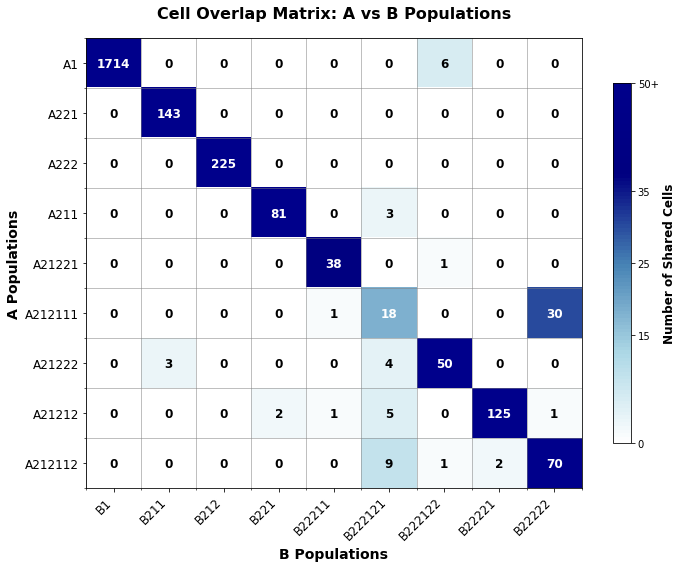


Overlap Matrix (A rows vs B cols):
Pop           B1    B211    B212    B221  B22211 B222121 B222122  B22221  B22222   Total
------------------------------------------------------------
A1          1714       0       0       0       0       0       6       0       0    1720
A221           0     143       0       0       0       0       0       0       0     143
A222           0       0     225       0       0       0       0       0       0     225
A211           0       0       0      81       0       3       0       0       0      84
A21221         0       0       0       0      38       0       1       0       0      39
A212111        0       0       0       0       1      18       0       0      30      49
A21222         0       3       0       0       0       4      50       0       0      57
A21212         0       0       0       2       1       5       0     125       1     134
A212112        0       0       0       0       0       9       1       2      70      82
-------------

In [9]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict)

In [10]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
data["lengths"] = data["abend"] - data["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()

In [11]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)

print("\n=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)

print(f"\nNormal population A: {normal_A}")
print(f"Normal population B: {normal_B}")

=== Population Set A Analysis ===
Normal population identified as: A1

=== Population Set B Analysis ===
Normal population identified as: B1

Normal population A: A1
Normal population B: B1


In [12]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A1_ratio  A211_ratio  \
0  chr1          0   45387037           0       1.0    0.878161   
1  chr1   45972336  119478274           1       1.0    1.672713   
2  chr1  120035598  175362842           2       1.0    2.332777   
3  chr1  175900450  182029442           3       1.0    1.682233   
4  chr1  182578512  248389233           4       1.0    0.857309   

   A212111_ratio  A212112_ratio  A21212_ratio  A21221_ratio  A21222_ratio  \
0       0.957530       0.957133      0.989565      0.887072      1.163883   
1       1.867634       1.712868      1.792870      1.705704      1.632474   
2       2.560779       2.317272      2.428685      1.922442      2.006818   
3       1.821195       1.702634      1.765015      2.329025      1.607322   
4       0.903335       0.875351      0.893311      1.274393      1.114694   

   A221_ratio  A222_ratio  
0    0.934190    0.988520  
1    1.785982    1.860042  
2    1.422486    1.501121  
3

In [13]:
# Perform ploidy optimization for each population in set A (excluding normal)
print("=== Ploidy Optimization for Population Set A ===")

# Get all population ratio columns (excluding normal population)
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results = compute_optimal_ploidy_and_profile(
        ratios_A, 
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

=== Ploidy Optimization for Population Set A ===
Normal population: A1
Populations to optimize: ['A211', 'A212111', 'A212112', 'A21212', 'A21221', 'A21222', 'A221', 'A222']

Optimizing ploidy for population: A211

Optimal Results for A211:
Optimal multiplier (m): 2.400
Minimum cost: 7.92e+07
Average copy number: 2.96
Optimal multiplier for A211: 2.400

Optimizing ploidy for population: A212111

Optimal Results for A212111:
Optimal multiplier (m): 2.100
Minimum cost: 9.16e+07
Average copy number: 2.90
Optimal multiplier for A212111: 2.100

Optimizing ploidy for population: A212112

Optimal Results for A212112:
Optimal multiplier (m): 2.400
Minimum cost: 5.22e+07
Average copy number: 2.90
Optimal multiplier for A212112: 2.400

Optimizing ploidy for population: A21212

Optimal Results for A21212:
Optimal multiplier (m): 2.300
Minimum cost: 5.56e+07
Average copy number: 2.94
Optimal multiplier for A21212: 2.300

Optimizing ploidy for population: A21221

Optimal Results for A21221:
Optimal 

In [14]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A211

Optimal Results for A211:
Optimal multiplier (m): 2.400
Minimum cost: 7.92e+07
Average copy number: 2.96
Found 6 local minima
Optimal multiplier for A211: 2.400
Found 6 local minima: ['2.40', '4.70', '5.50', '3.10', '3.70']

Optimizing ploidy for population: A212111

Optimal Results for A212111:
Optimal multiplier (m): 2.100
Minimum cost: 9.16e+07
Average copy number: 2.90
Found 6 local minima
Optimal multiplier for A212111: 2.100
Found 6 local minima: ['2.10', '4.30', '5.40', '2.80', '3.10']

Optimizing ploidy for population: A212112

Optimal Results for A212112:
Optimal multiplier (m): 2.400
Minimum cost: 5.22e+07
Average copy number: 2.90
Found 6 local minima
Optimal multiplier for A212112: 2.400
Found 6 local minima: ['2.40', '4.80', '5.70', '3.20', '3.80']

Optimizing ploidy for population: A21212

Optimal Results for A21212:
Optimal multiplier (m): 2.300
Minimum cost: 5.56e+07
Average copy number: 2.94
Found 6 local minima
Optimal multipli


Plotting results for population: A211


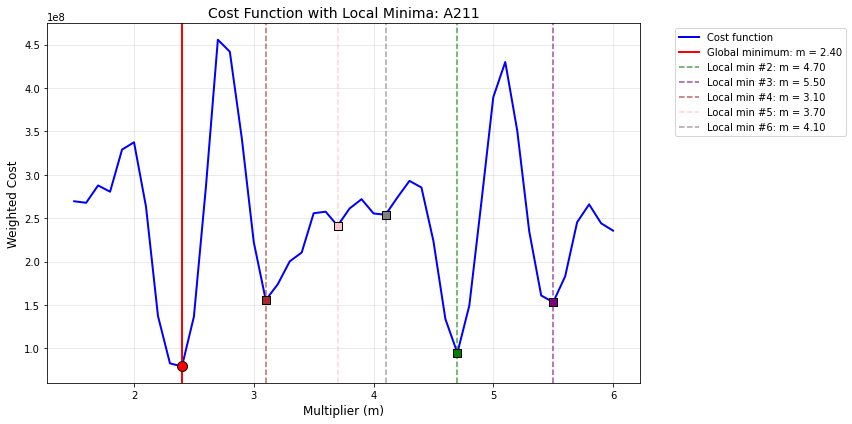


Local Minima Summary for A211:
--------------------------------------------------
#1: m = 2.40, cost = 7.92e+07 (GLOBAL)
#2: m = 4.70, cost = 9.48e+07
#3: m = 5.50, cost = 1.53e+08
#4: m = 3.10, cost = 1.56e+08
#5: m = 3.70, cost = 2.41e+08
#6: m = 4.10, cost = 2.54e+08


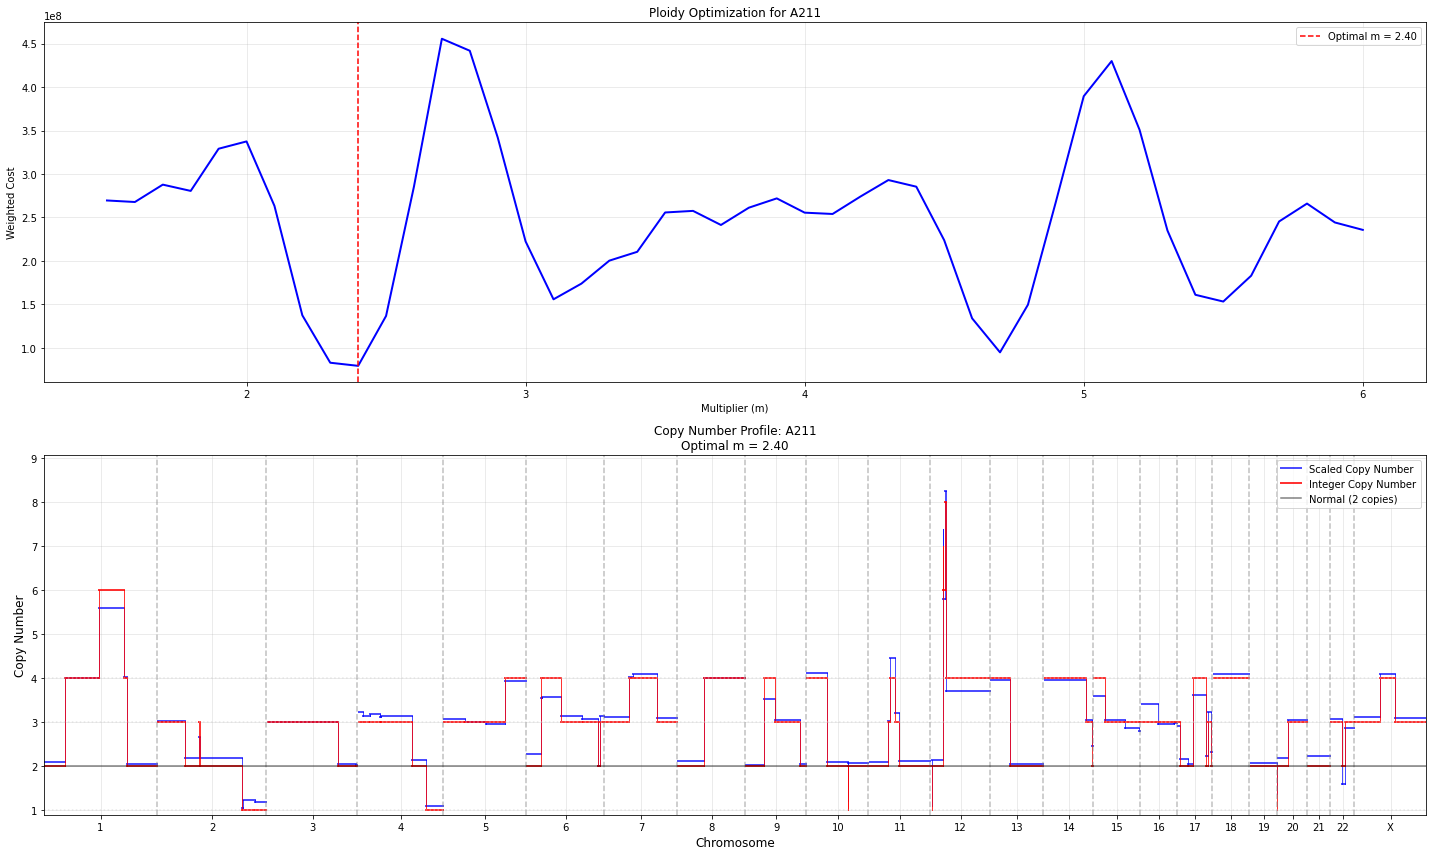

Completed plots for A211

Plotting results for population: A212111


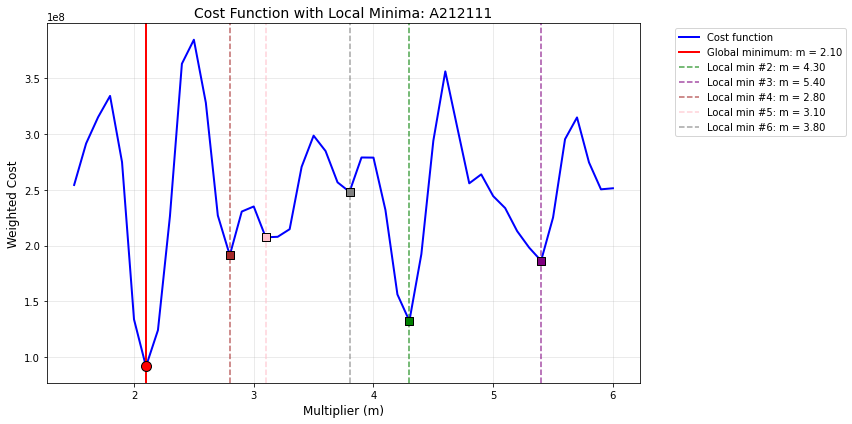


Local Minima Summary for A212111:
--------------------------------------------------
#1: m = 2.10, cost = 9.16e+07 (GLOBAL)
#2: m = 4.30, cost = 1.32e+08
#3: m = 5.40, cost = 1.86e+08
#4: m = 2.80, cost = 1.91e+08
#5: m = 3.10, cost = 2.07e+08
#6: m = 3.80, cost = 2.48e+08


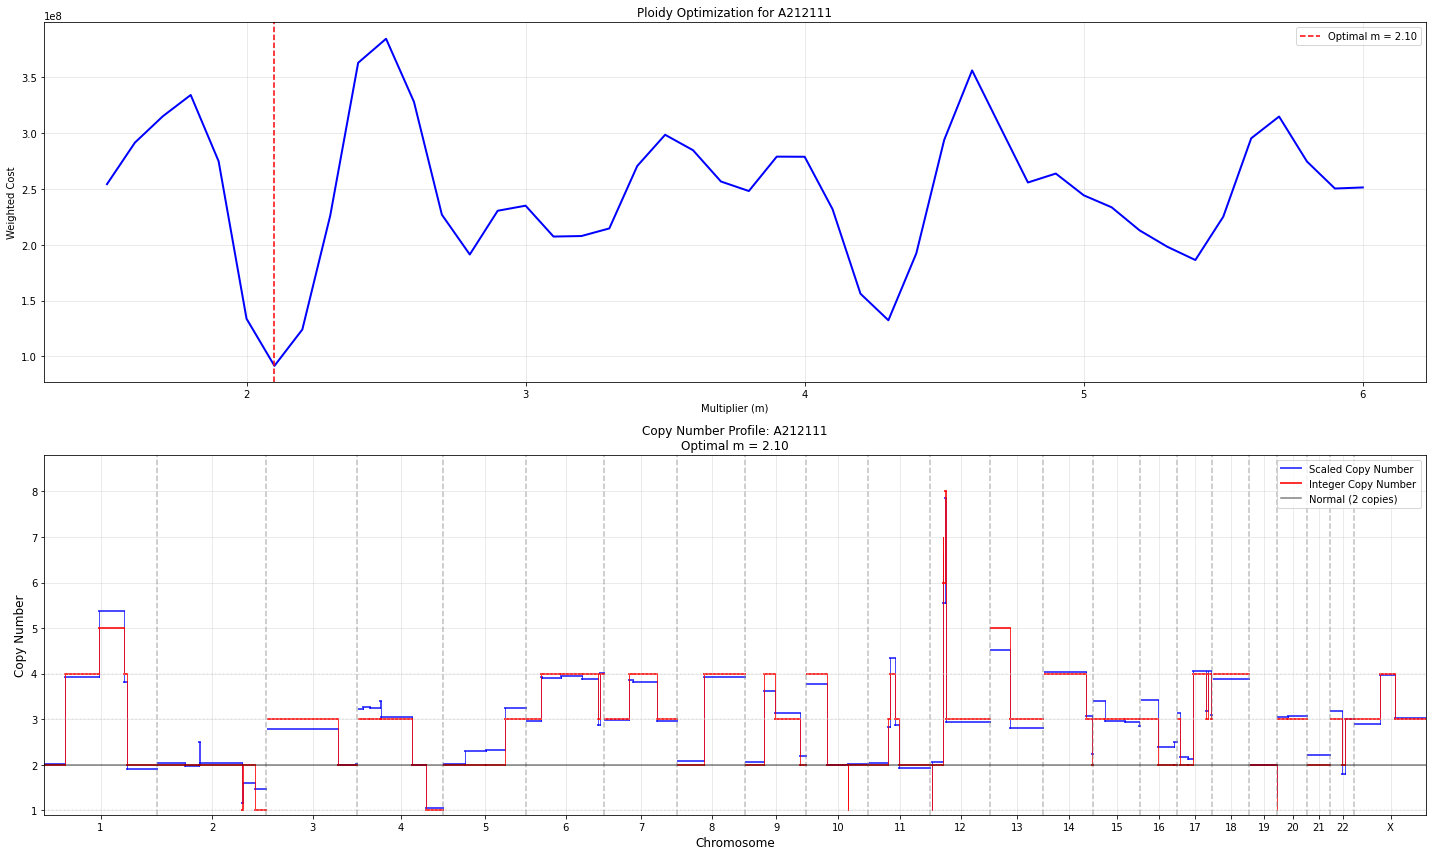

Completed plots for A212111

Plotting results for population: A212112


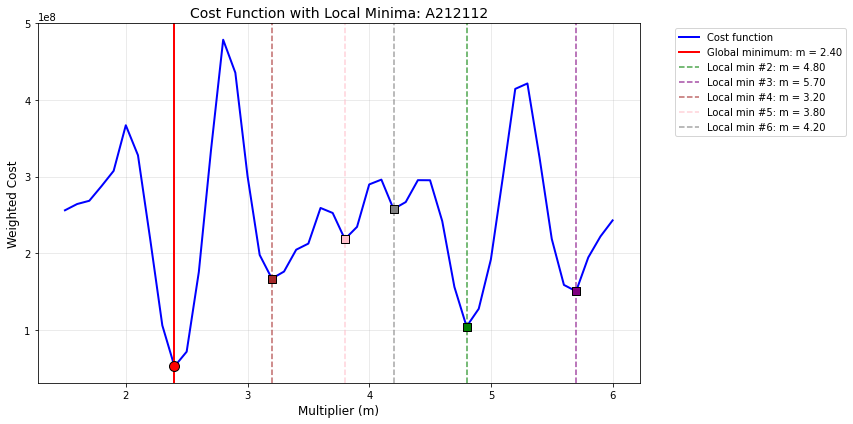


Local Minima Summary for A212112:
--------------------------------------------------
#1: m = 2.40, cost = 5.22e+07 (GLOBAL)
#2: m = 4.80, cost = 1.04e+08
#3: m = 5.70, cost = 1.50e+08
#4: m = 3.20, cost = 1.67e+08
#5: m = 3.80, cost = 2.18e+08
#6: m = 4.20, cost = 2.58e+08


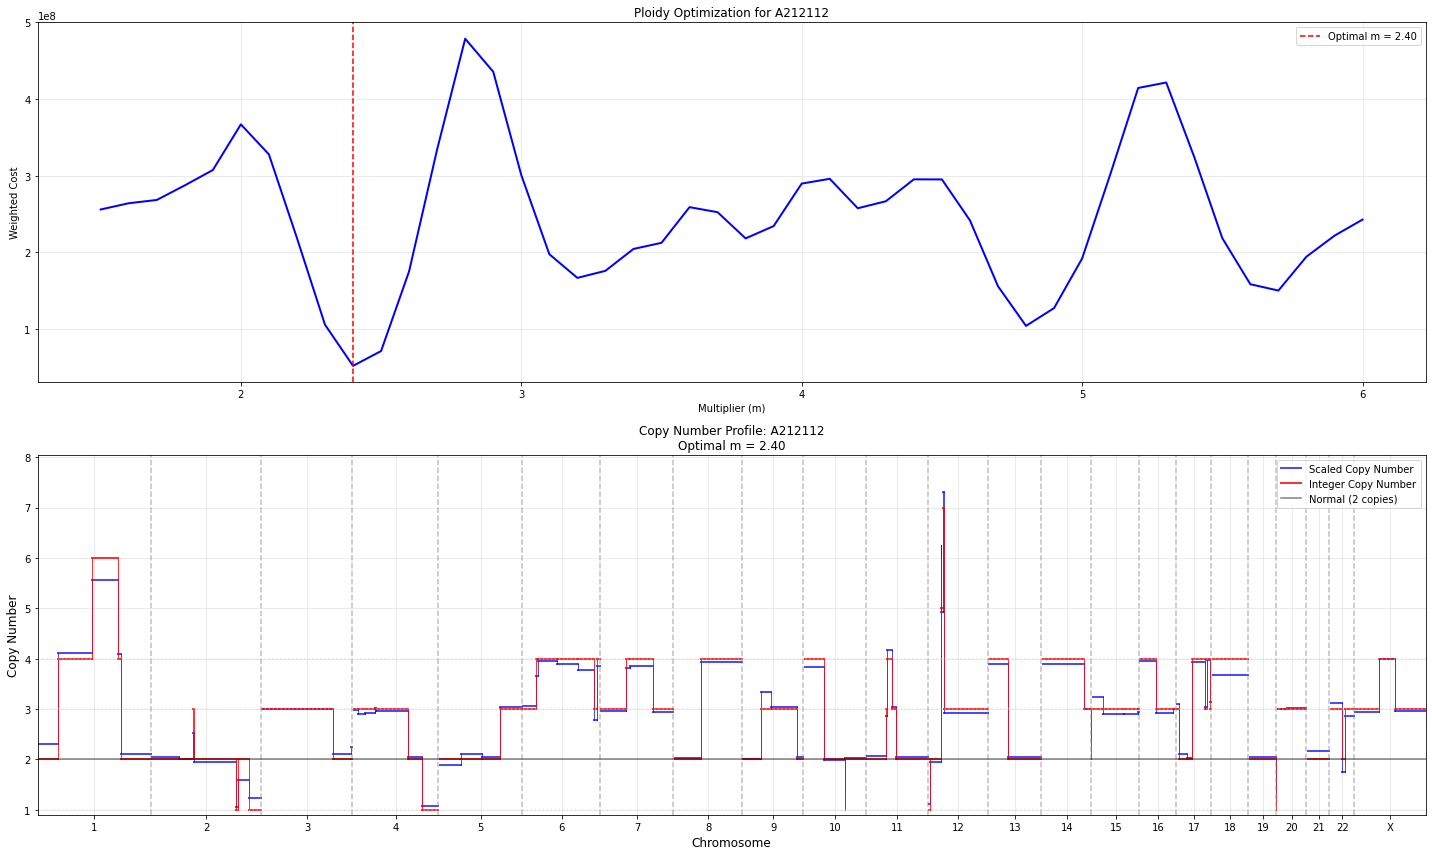

Completed plots for A212112

Plotting results for population: A21212


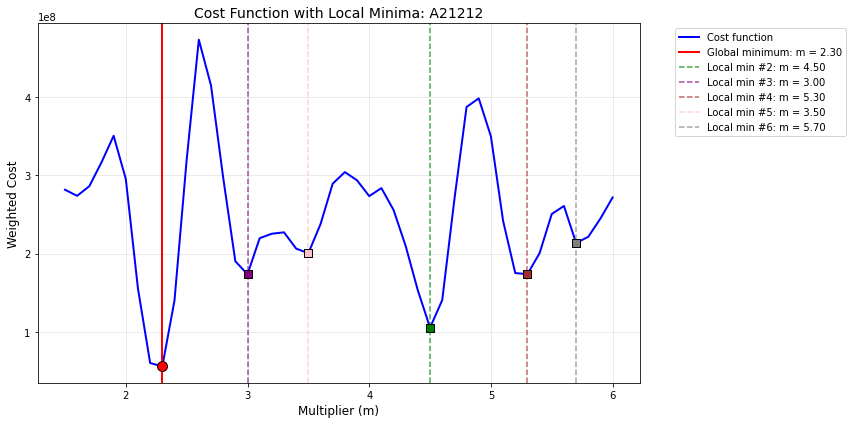


Local Minima Summary for A21212:
--------------------------------------------------
#1: m = 2.30, cost = 5.56e+07 (GLOBAL)
#2: m = 4.50, cost = 1.05e+08
#3: m = 3.00, cost = 1.74e+08
#4: m = 5.30, cost = 1.74e+08
#5: m = 3.50, cost = 2.00e+08
#6: m = 5.70, cost = 2.13e+08


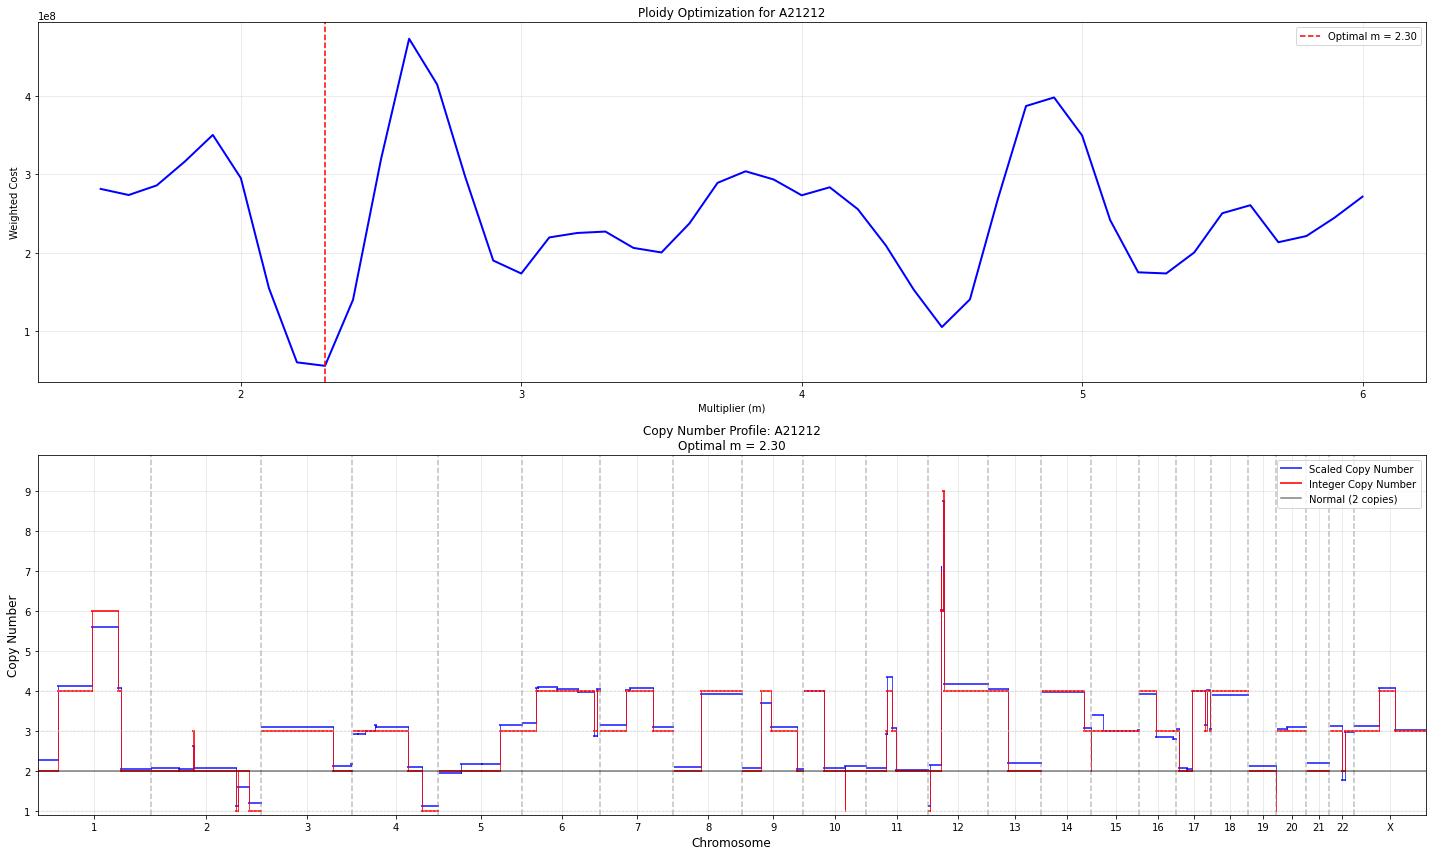

Completed plots for A21212

Plotting results for population: A21221


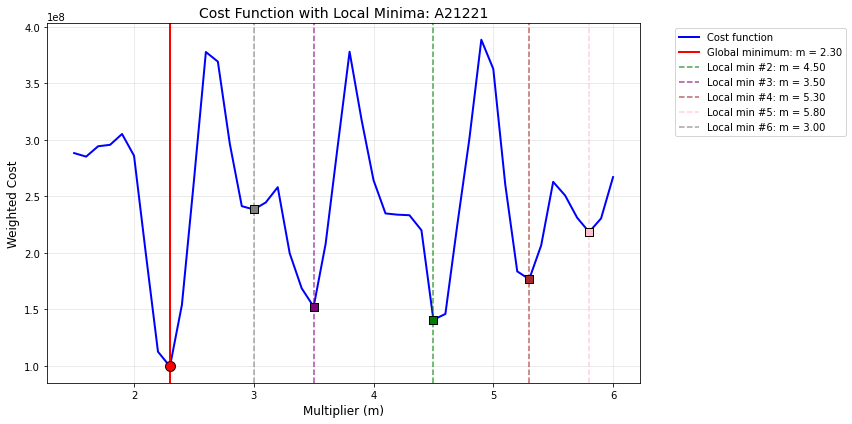


Local Minima Summary for A21221:
--------------------------------------------------
#1: m = 2.30, cost = 9.95e+07 (GLOBAL)
#2: m = 4.50, cost = 1.41e+08
#3: m = 3.50, cost = 1.52e+08
#4: m = 5.30, cost = 1.77e+08
#5: m = 5.80, cost = 2.18e+08
#6: m = 3.00, cost = 2.38e+08


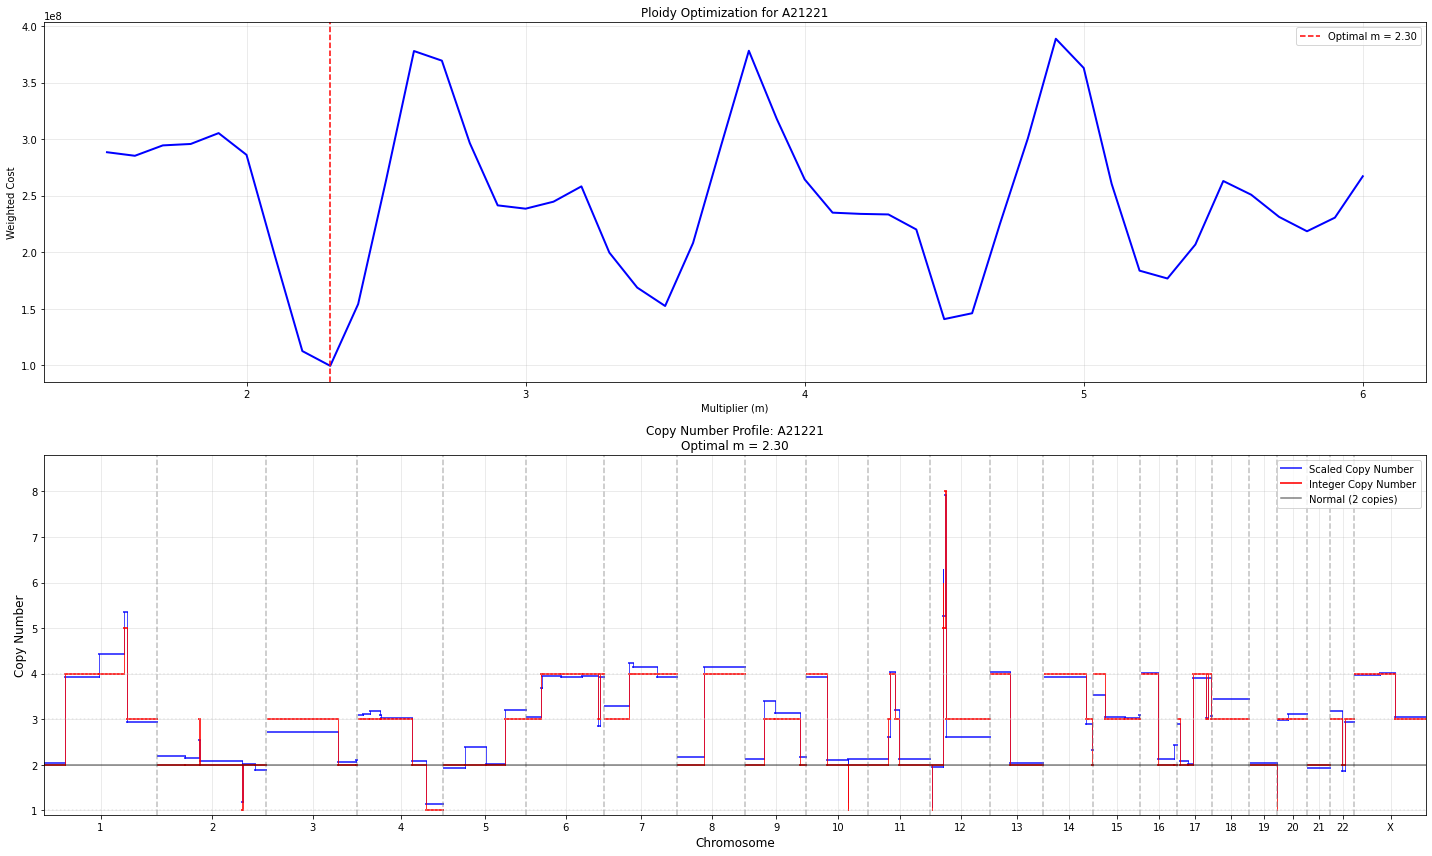

Completed plots for A21221

Plotting results for population: A21222


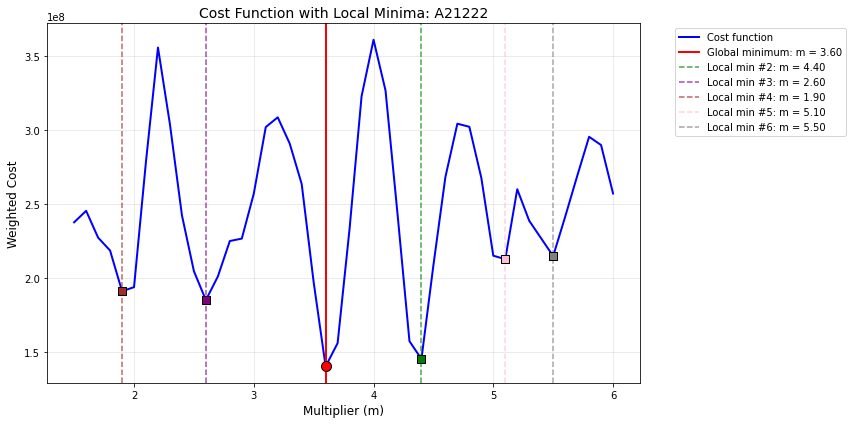


Local Minima Summary for A21222:
--------------------------------------------------
#1: m = 3.60, cost = 1.40e+08 (GLOBAL)
#2: m = 4.40, cost = 1.45e+08
#3: m = 2.60, cost = 1.85e+08
#4: m = 1.90, cost = 1.91e+08
#5: m = 5.10, cost = 2.13e+08
#6: m = 5.50, cost = 2.15e+08


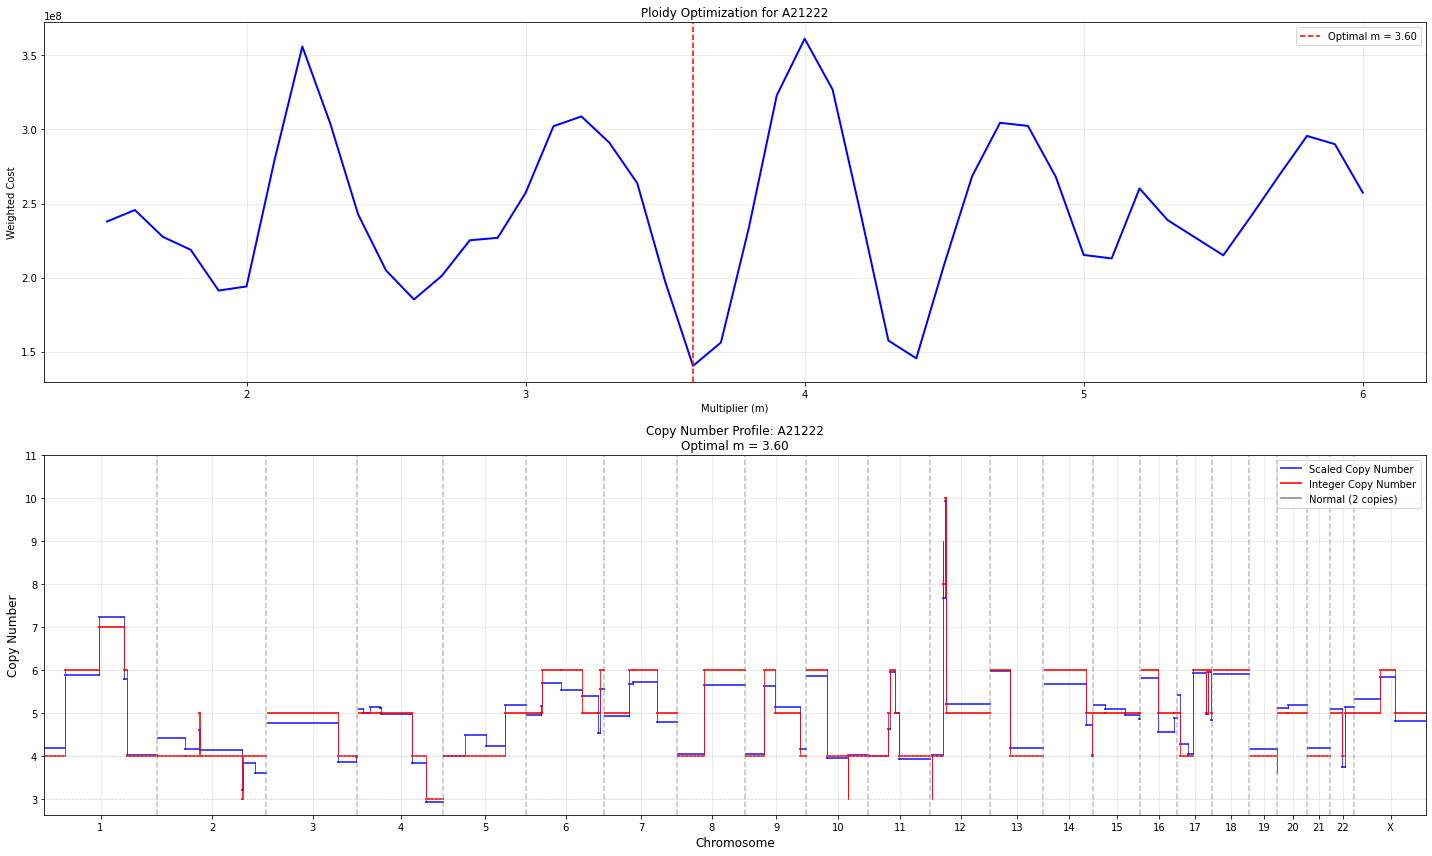

Completed plots for A21222

Plotting results for population: A221


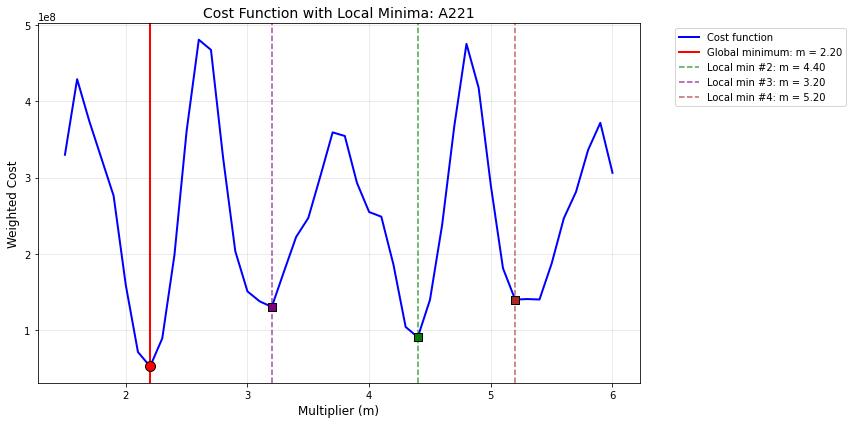


Local Minima Summary for A221:
--------------------------------------------------
#1: m = 2.20, cost = 5.23e+07 (GLOBAL)
#2: m = 4.40, cost = 9.07e+07
#3: m = 3.20, cost = 1.30e+08
#4: m = 5.20, cost = 1.40e+08


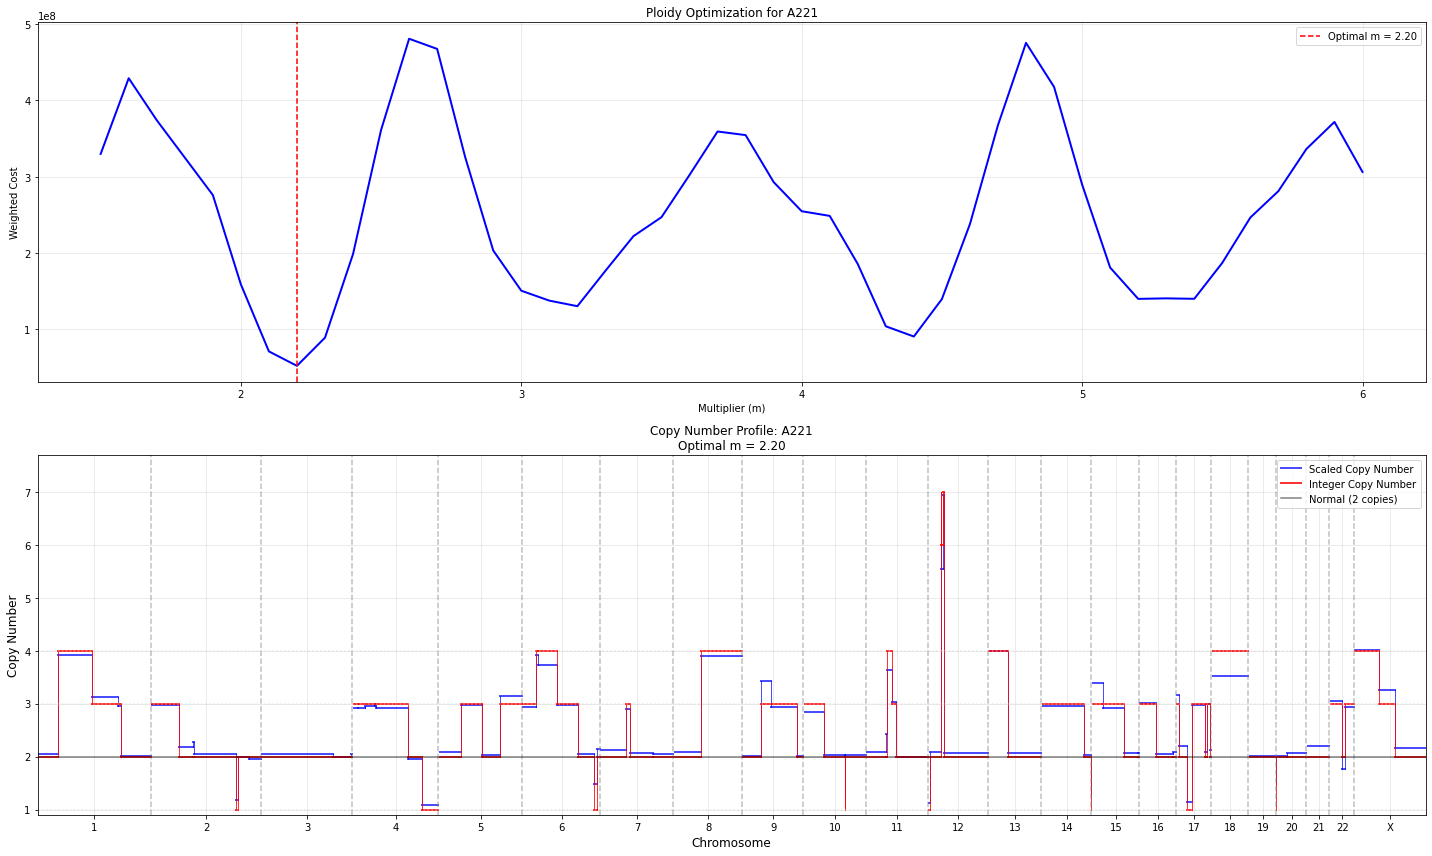

Completed plots for A221

Plotting results for population: A222


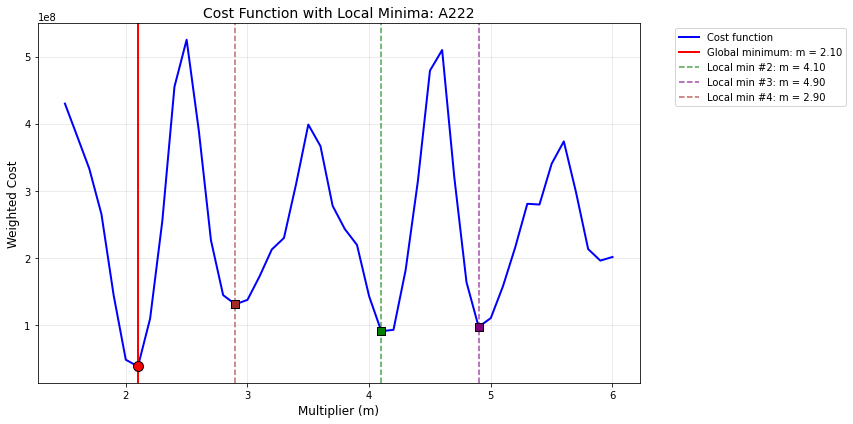


Local Minima Summary for A222:
--------------------------------------------------
#1: m = 2.10, cost = 3.83e+07 (GLOBAL)
#2: m = 4.10, cost = 9.08e+07
#3: m = 4.90, cost = 9.72e+07
#4: m = 2.90, cost = 1.31e+08


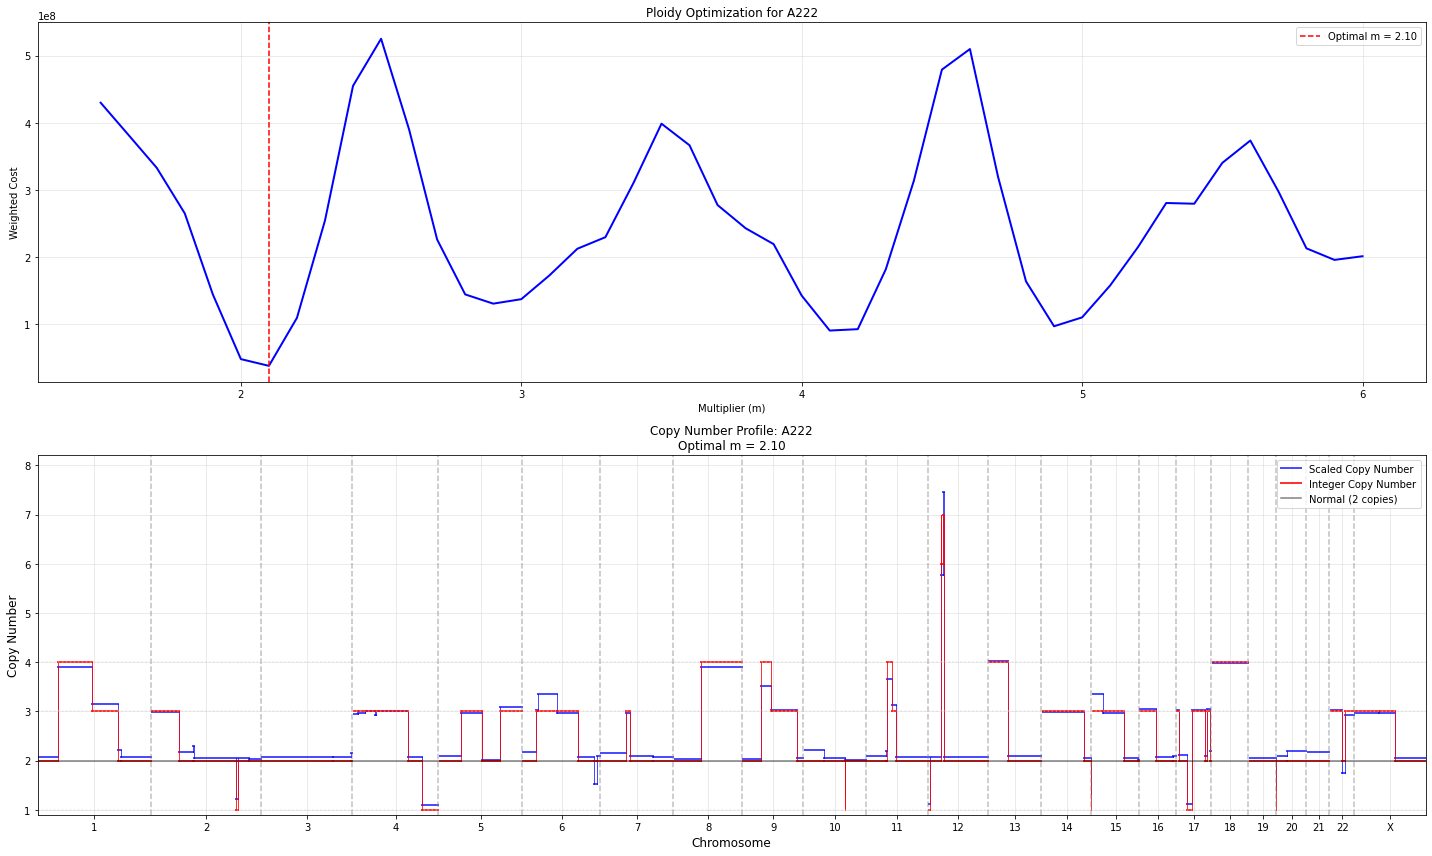

Completed plots for A222


In [15]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [16]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = "../data/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/t57/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8605992, 6)
hap_count_df ready for analysis!


In [17]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,AATGAGGATGCAACACA,3,6
1,chr1,1925685,1,AATGAGGATGCAACACA,0,2
2,chr1,3106884,2,AATGAGGATGCAACACA,0,2
3,chr1,4351684,3,AATGAGGATGCAACACA,7,7
4,chr1,5438445,4,AATGAGGATGCAACACA,0,0


In [18]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

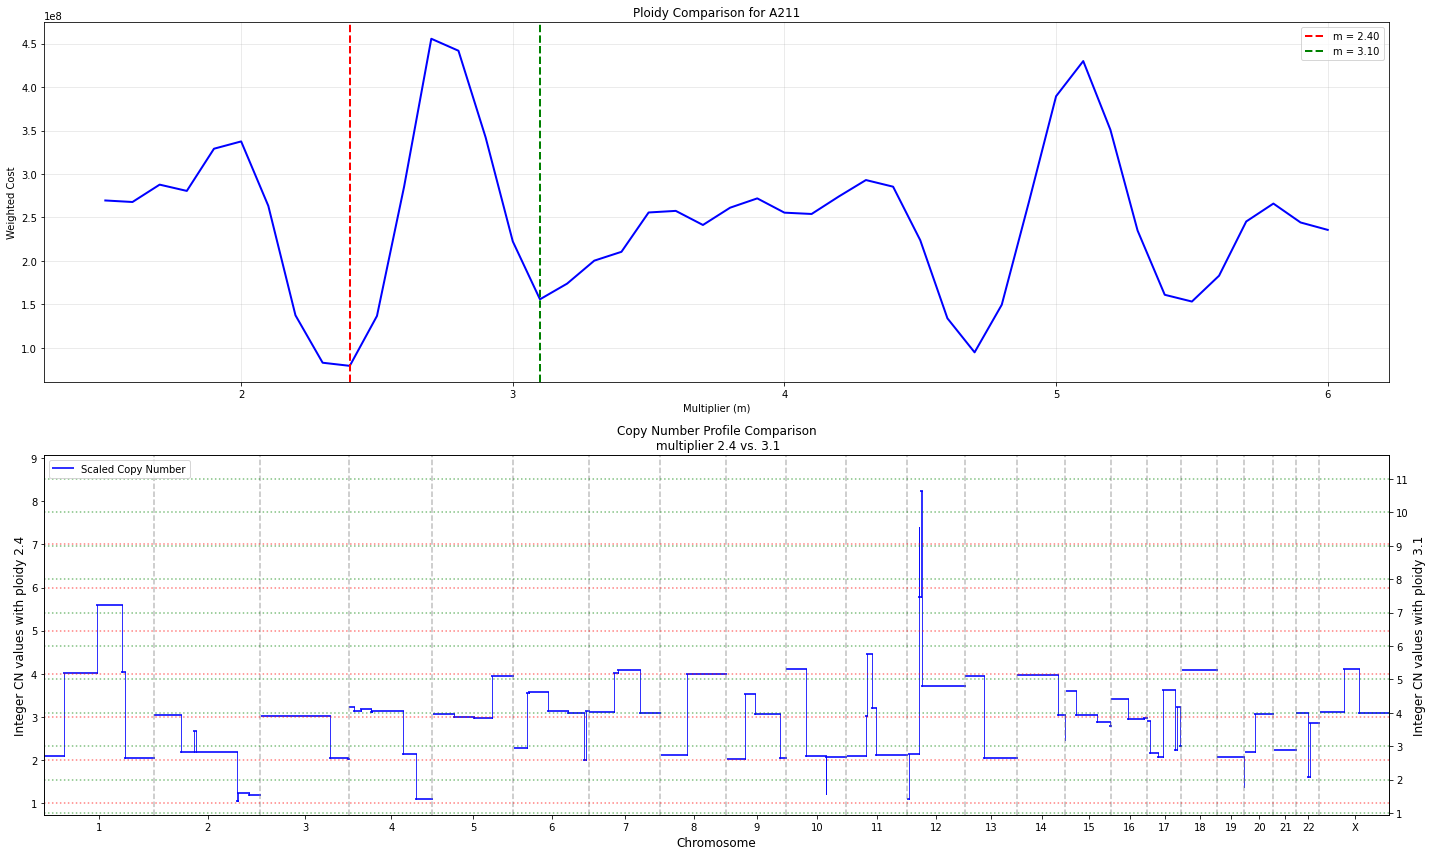

In [19]:
# Example usage for A211 with global min 2.4 and local min 3.1
plot_ploidy_comparison(
    results_df=profile_dfs_A['A211'],
    cost_results=ploidy_results_A['A211']['cost_results'],
    optimal_m=2.4,  # or use ploidy_results_A['A211']['optimal_multiplier']
    local_m=3.1,   # pick from ploidy_results_A['A211']['local_minima']
    pop_col='A211_ratio'
)

In [20]:
#Get all cells in A211
A211_cells = A_dict['A211']['cells']
#Filter hap_count_df for these cells
A211_hap_df = hap_count_df[hap_count_df['cell'].isin(A211_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
A211_hap_ratio = A211_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
A211_hap_ratio['hap_ratio'] = A211_hap_ratio['hap_count'] / A211_hap_ratio['Total']
A211_hap_ratio['folded'] = A211_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
A211_hap_ratio["chrom"] = A211_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])


In [21]:
A211_hap_ratio.head()

,bin,abspos,hap_count,Total,hap_ratio,folded,chrom
0,0,0,139,274,0.507299,0.492701,chr1
1,1,1925685,220,275,0.800000,0.200000,chr1
2,2,3106884,258,410,0.629268,0.370732,chr1
3,3,4351684,211,380,0.555263,0.444737,chr1
4,4,5438445,44,108,0.407407,0.407407,chr1


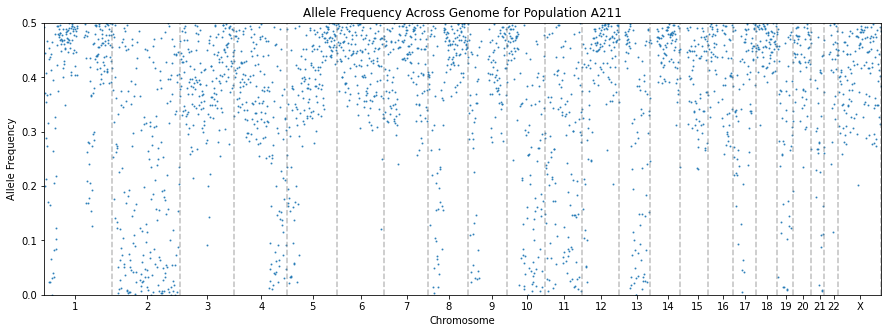

In [22]:
# plot the folded allele frequency along the genome
A211_hap_ratio_sorted = A211_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(A211_hap_ratio_sorted['abspos'], A211_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population A211')
# Add vertical lines for chromosome boundaries
chrom_boundaries = A211_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = A211_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(A211_hap_ratio_sorted['abspos'].min(), A211_hap_ratio_sorted['abspos'].max())
plt.show()

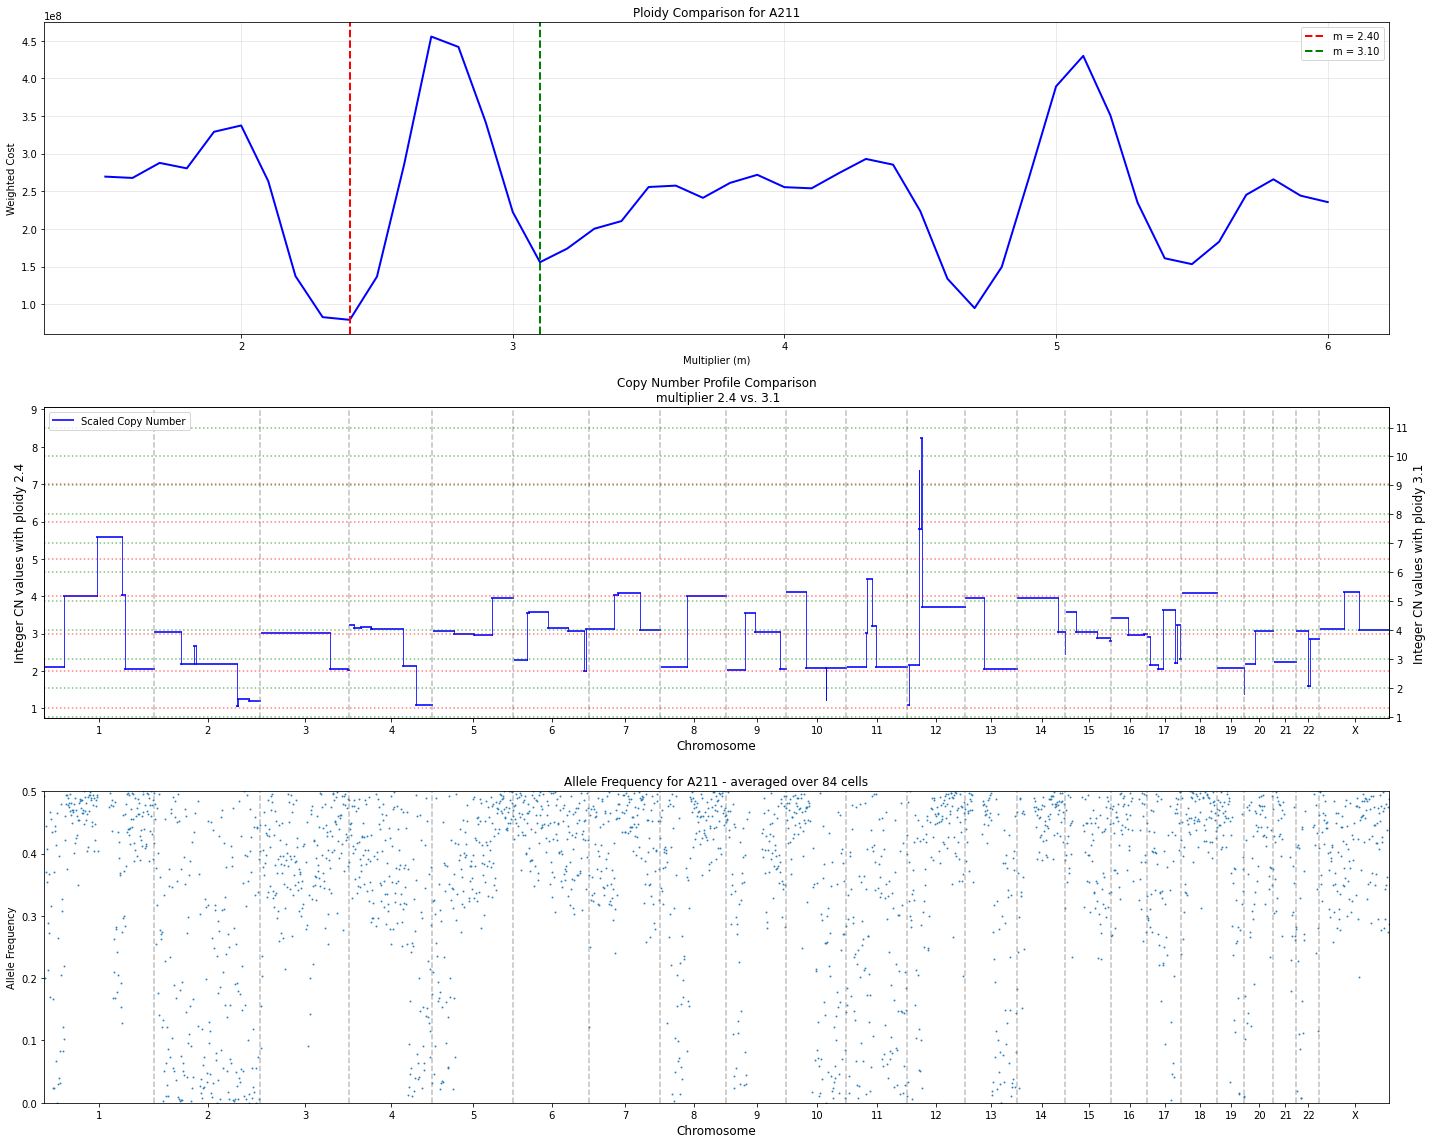

In [23]:
# Example usage for A211 with global min 2.4 and local min 3.1
plot_ploidy_comparison(
    results_df=profile_dfs_A['A211'],
    cost_results=ploidy_results_A['A211']['cost_results'],
    optimal_m=2.4,
    local_m=3.1,
    pop_col='A211_ratio',
    hap_count_df=hap_count_df,
    cells=A_dict['A211']['cells']
)


Creating ploidy comparison for population: A211


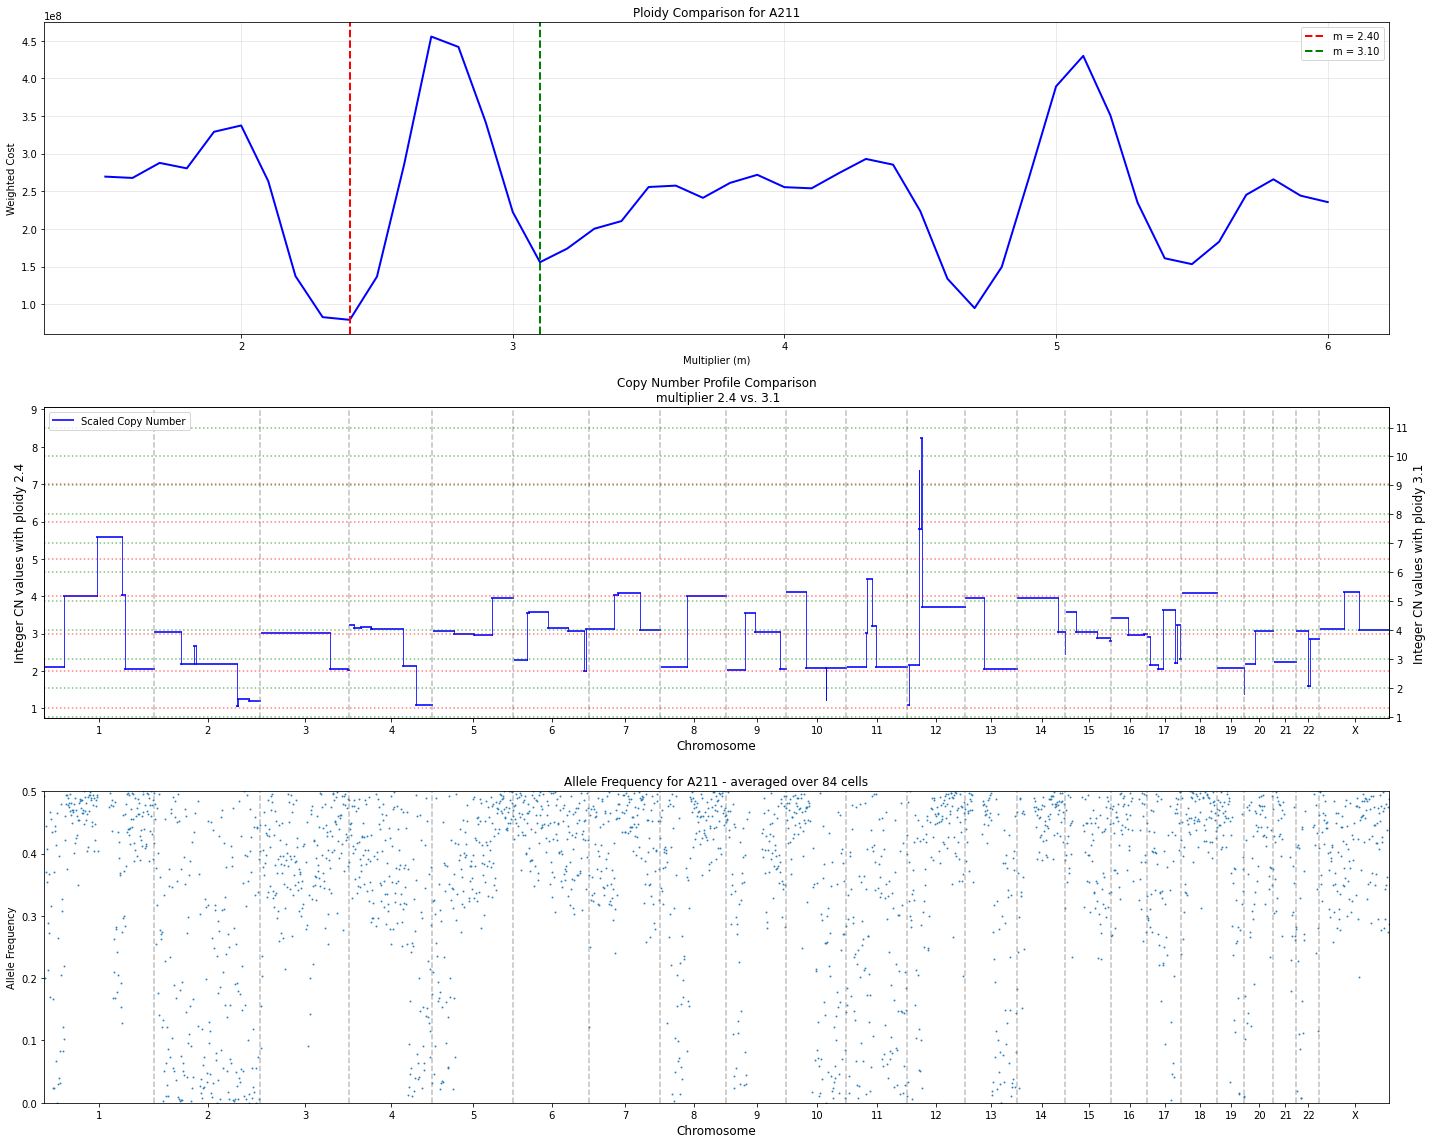

Compared 2.40 vs 3.10 for A211

Creating ploidy comparison for population: A212111


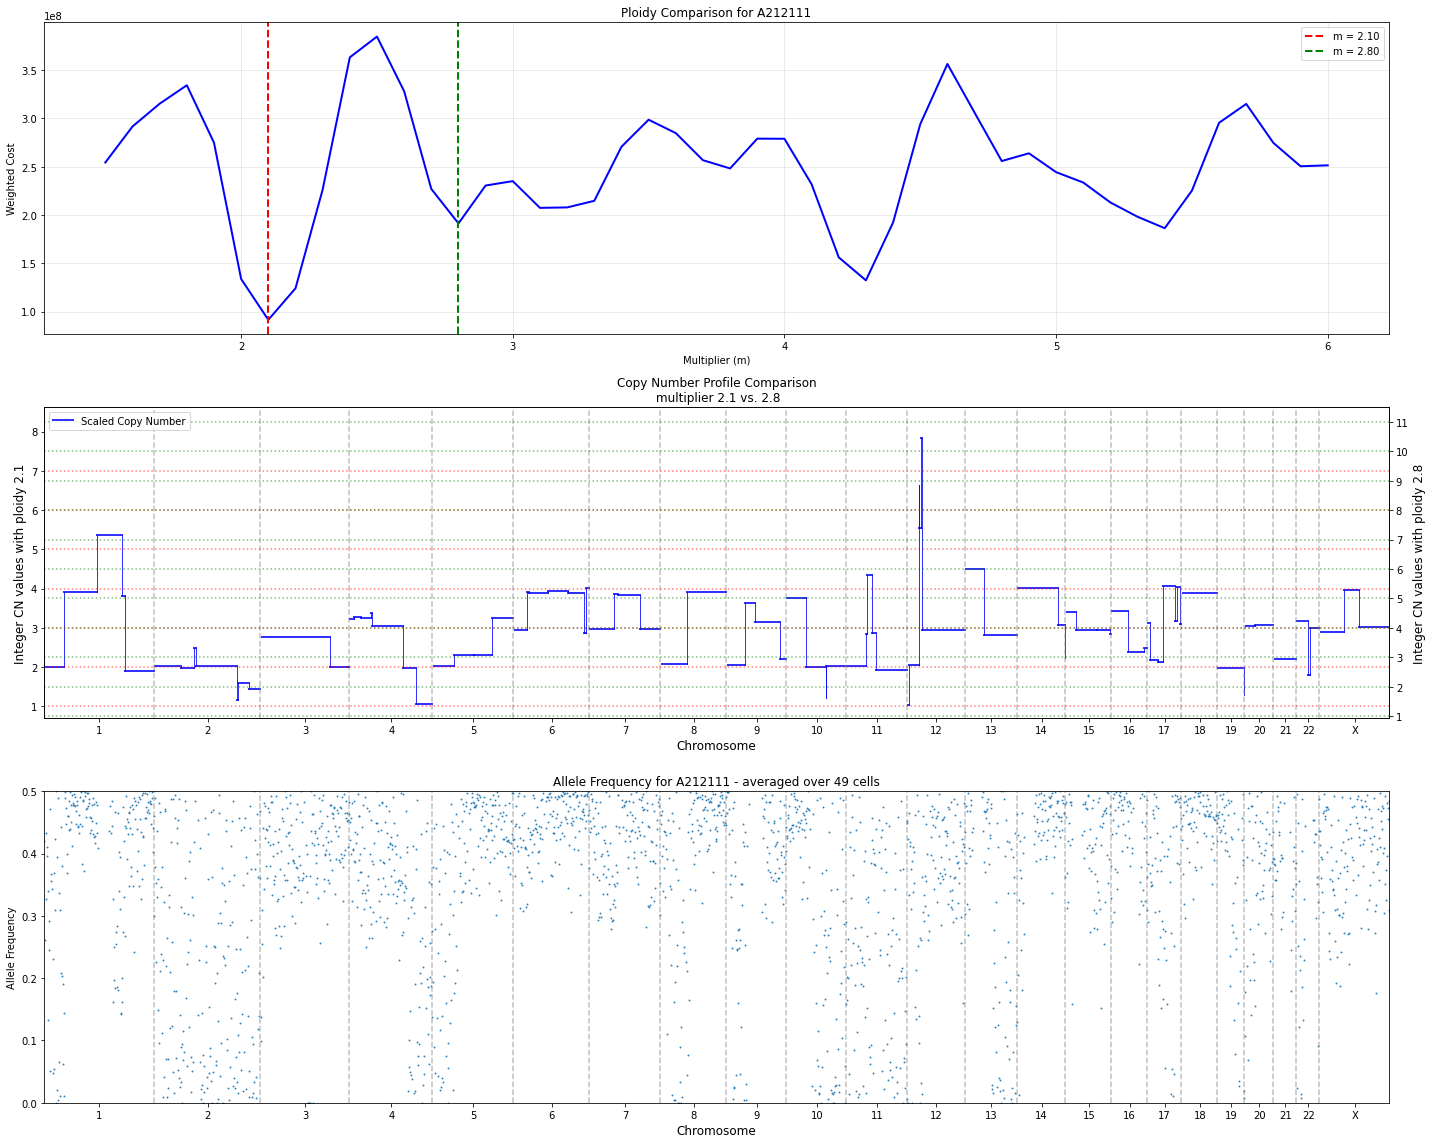

Compared 2.10 vs 2.80 for A212111

Creating ploidy comparison for population: A212112


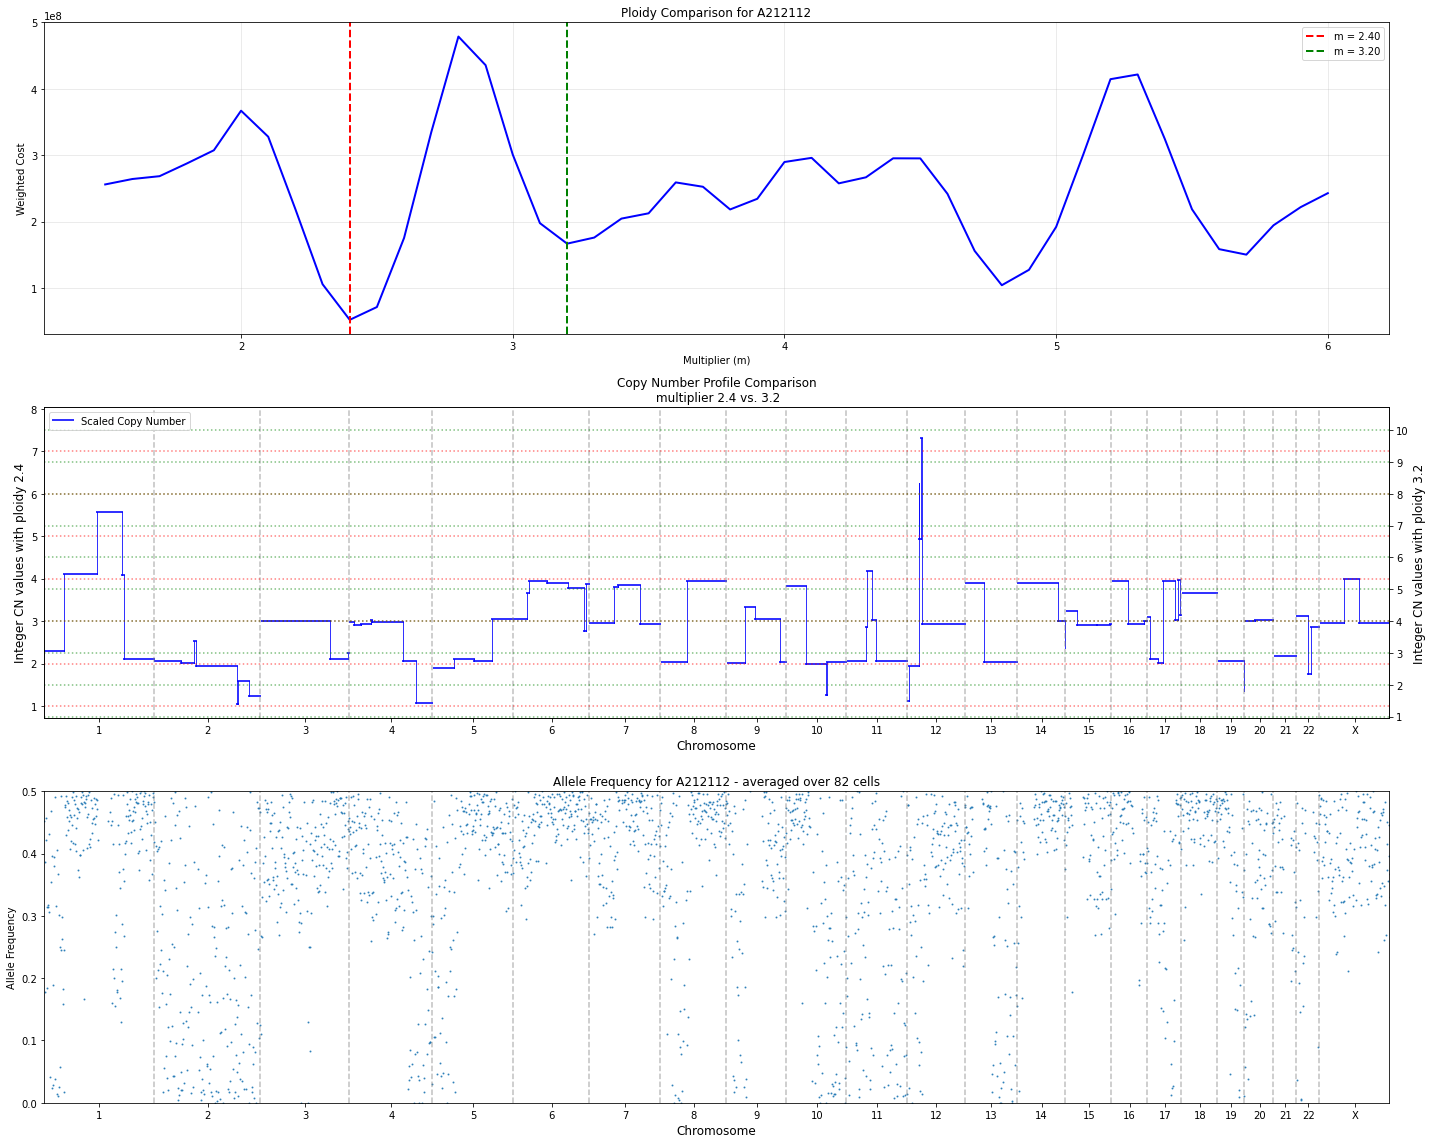

Compared 2.40 vs 3.20 for A212112

Creating ploidy comparison for population: A21212


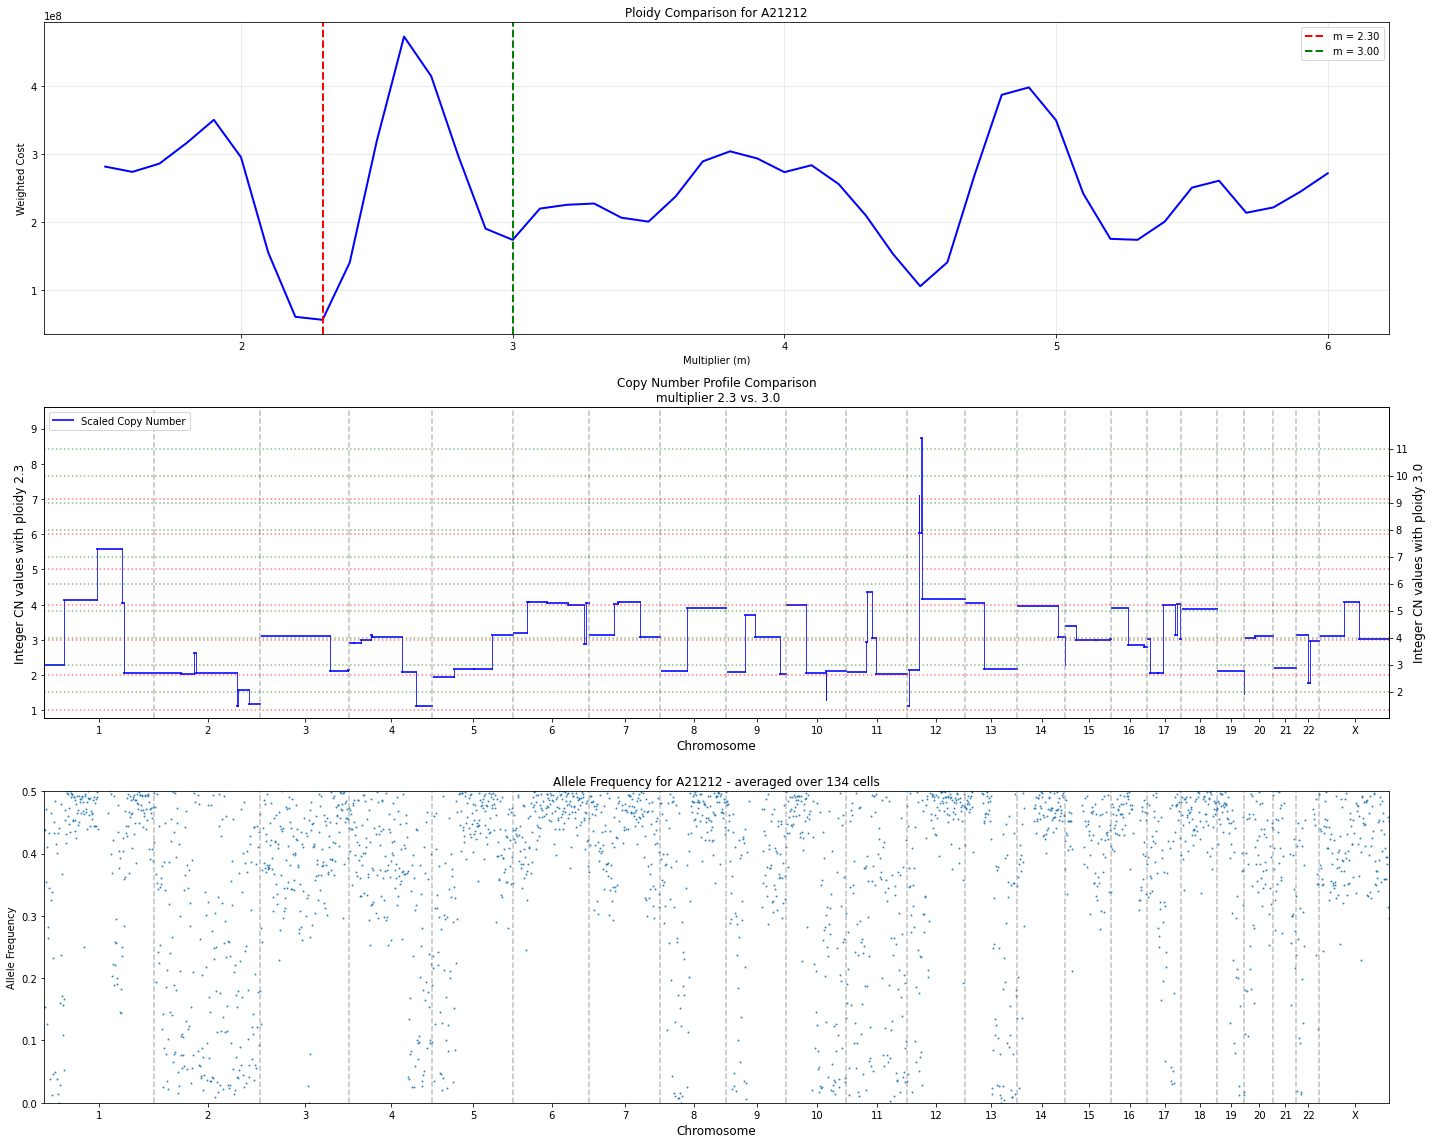

Compared 2.30 vs 3.00 for A21212

Creating ploidy comparison for population: A21221


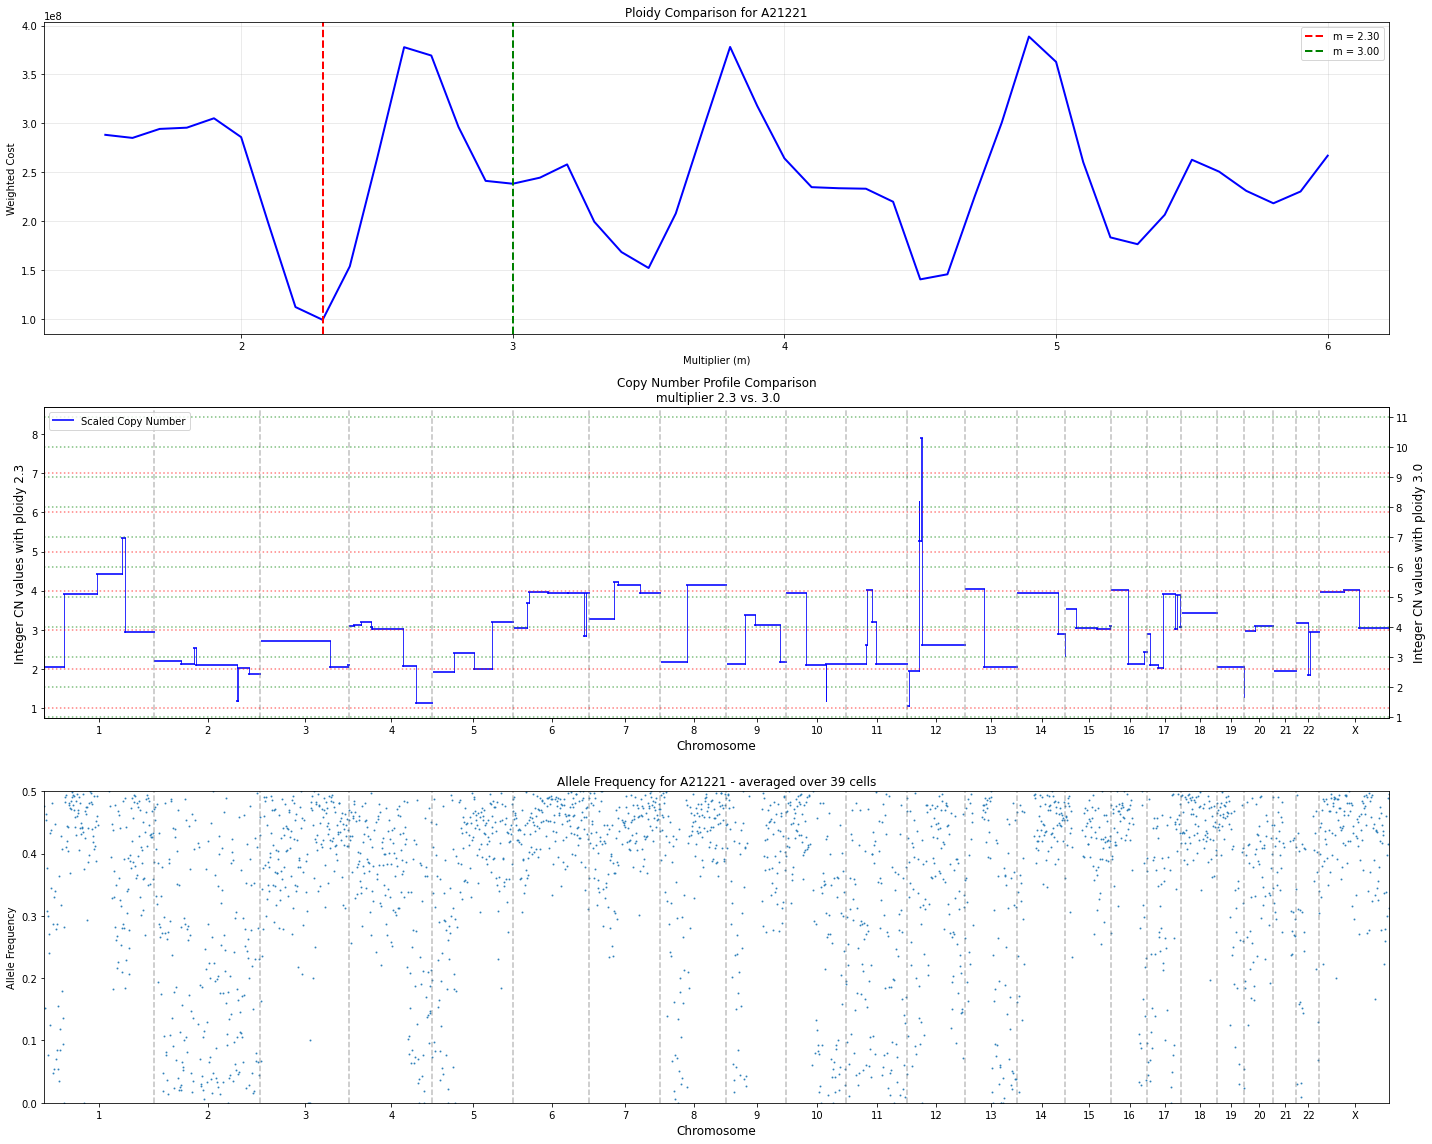

Compared 2.30 vs 3.00 for A21221

Creating ploidy comparison for population: A21222


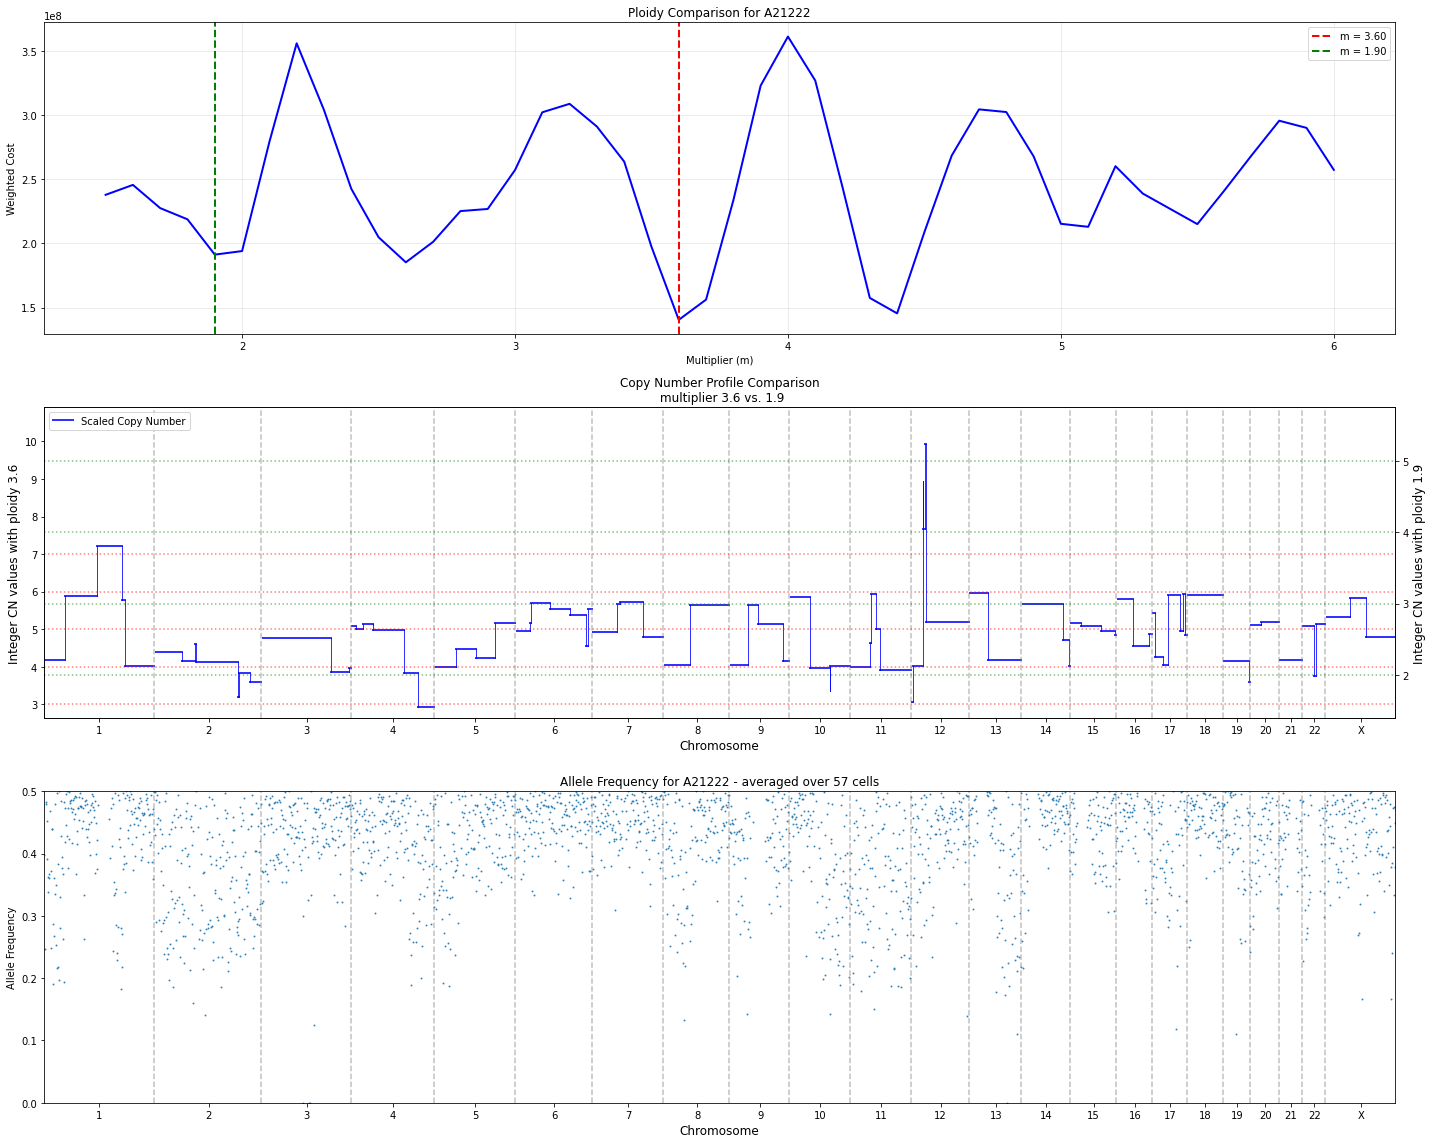

Compared 3.60 vs 1.90 for A21222

Creating ploidy comparison for population: A221


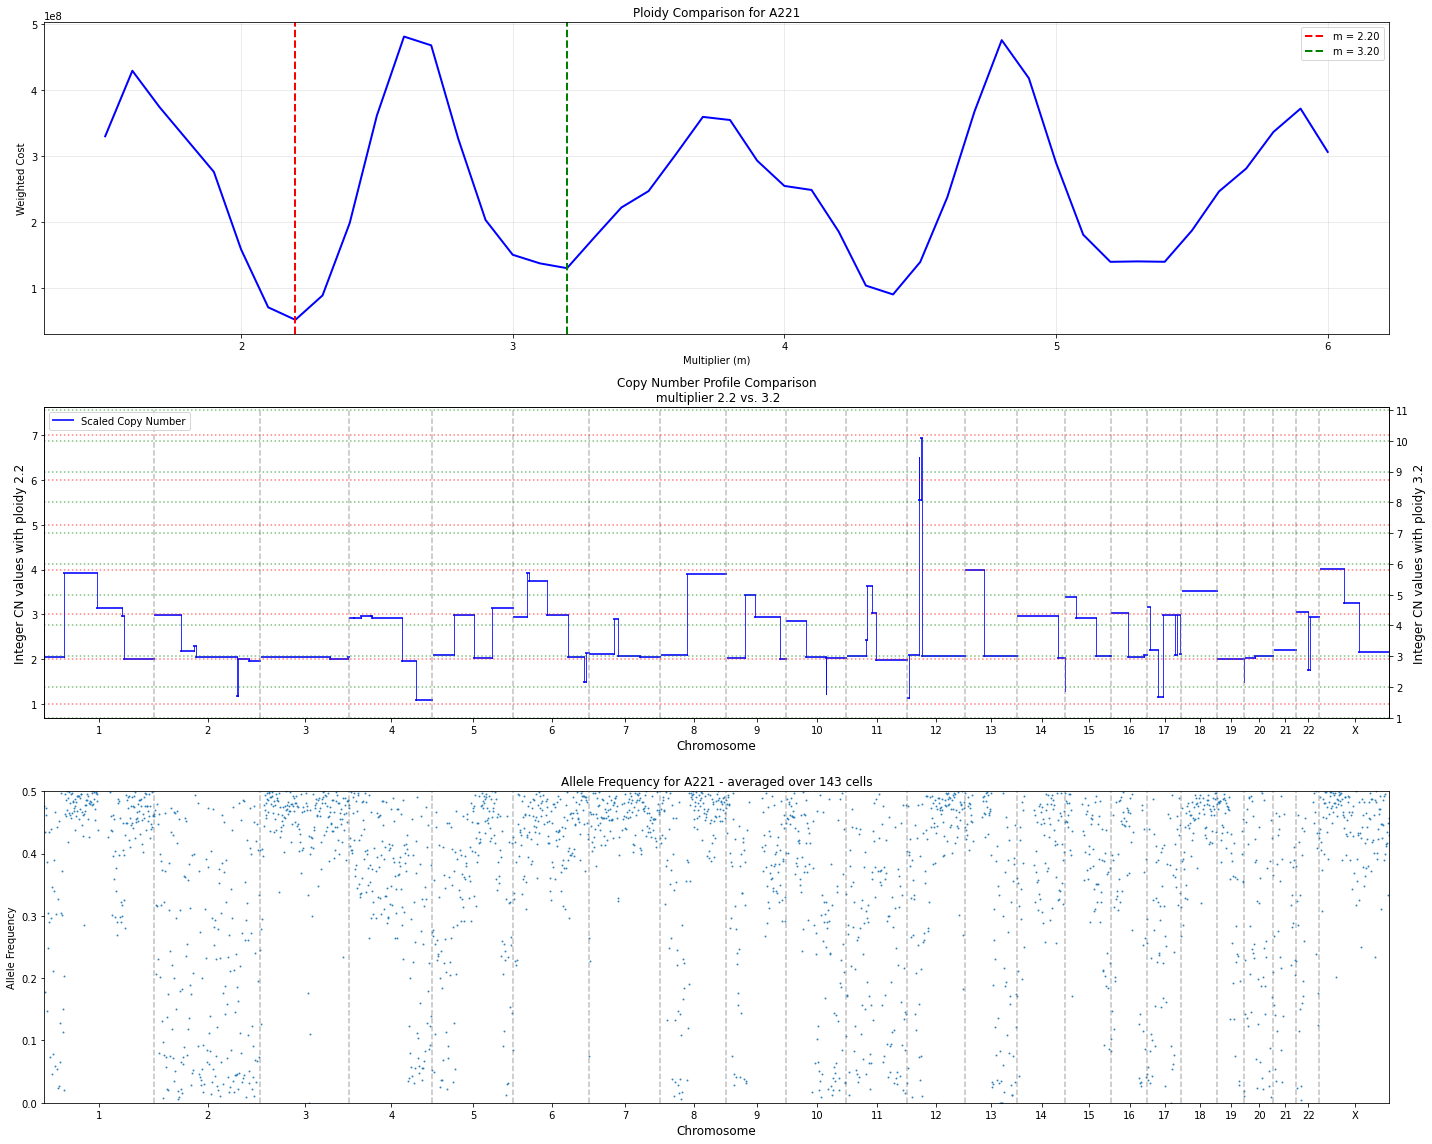

Compared 2.20 vs 3.20 for A221

Creating ploidy comparison for population: A222


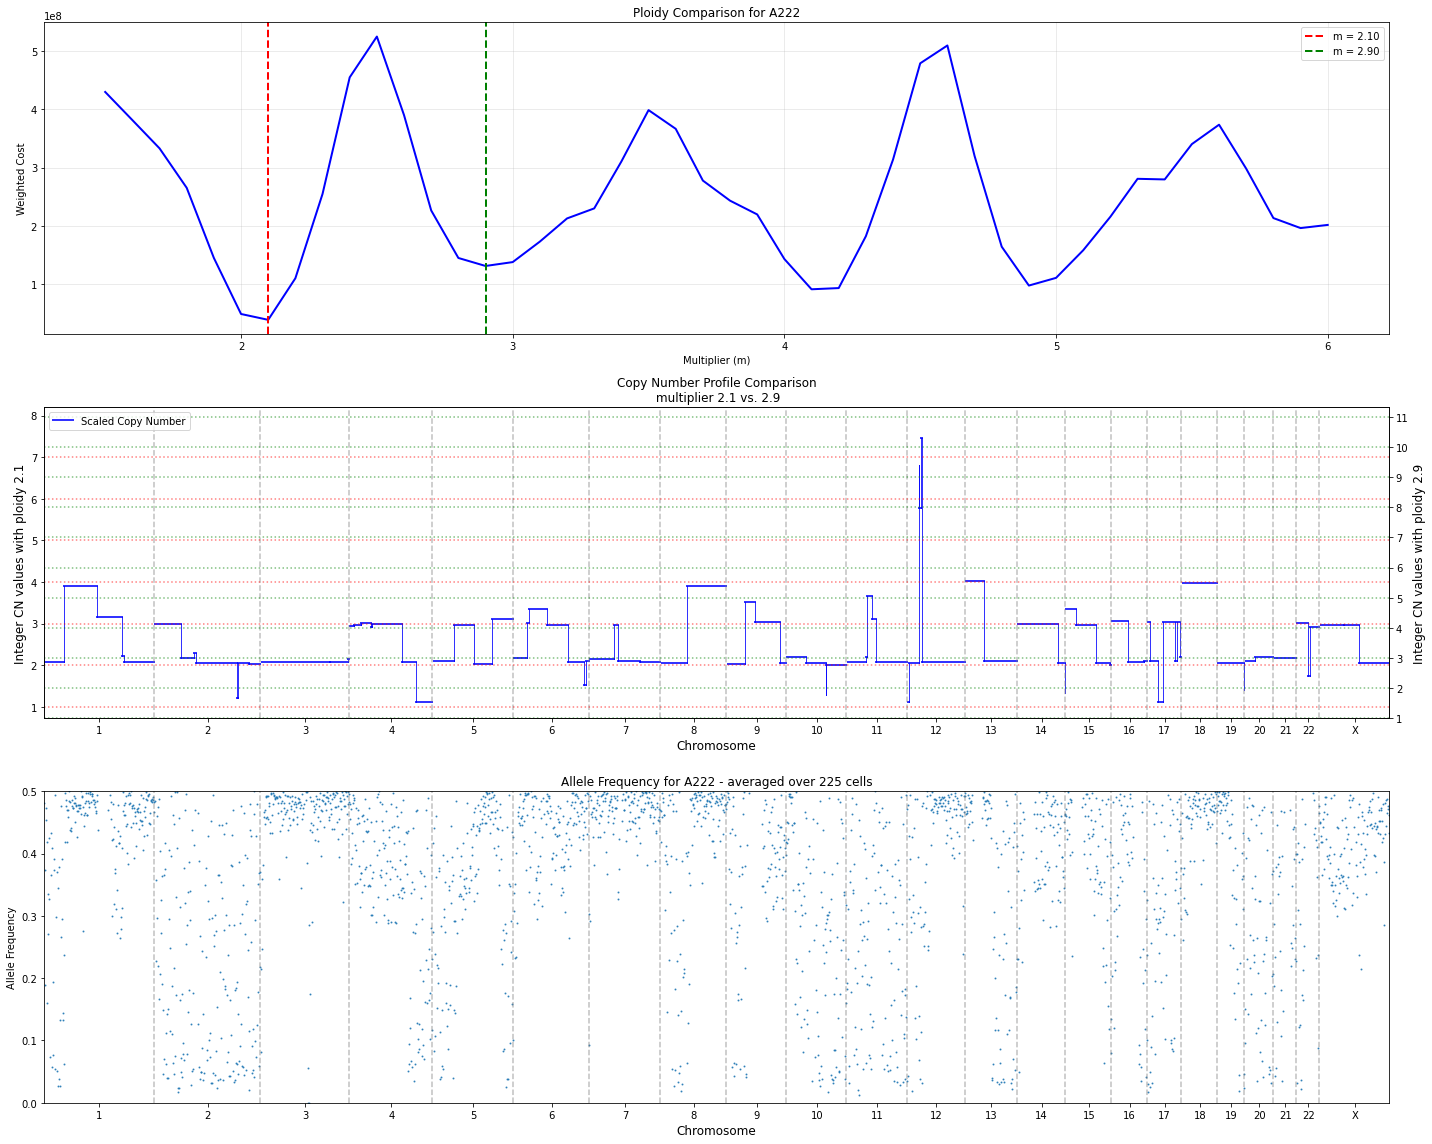

Compared 2.10 vs 2.90 for A222


In [24]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: A211


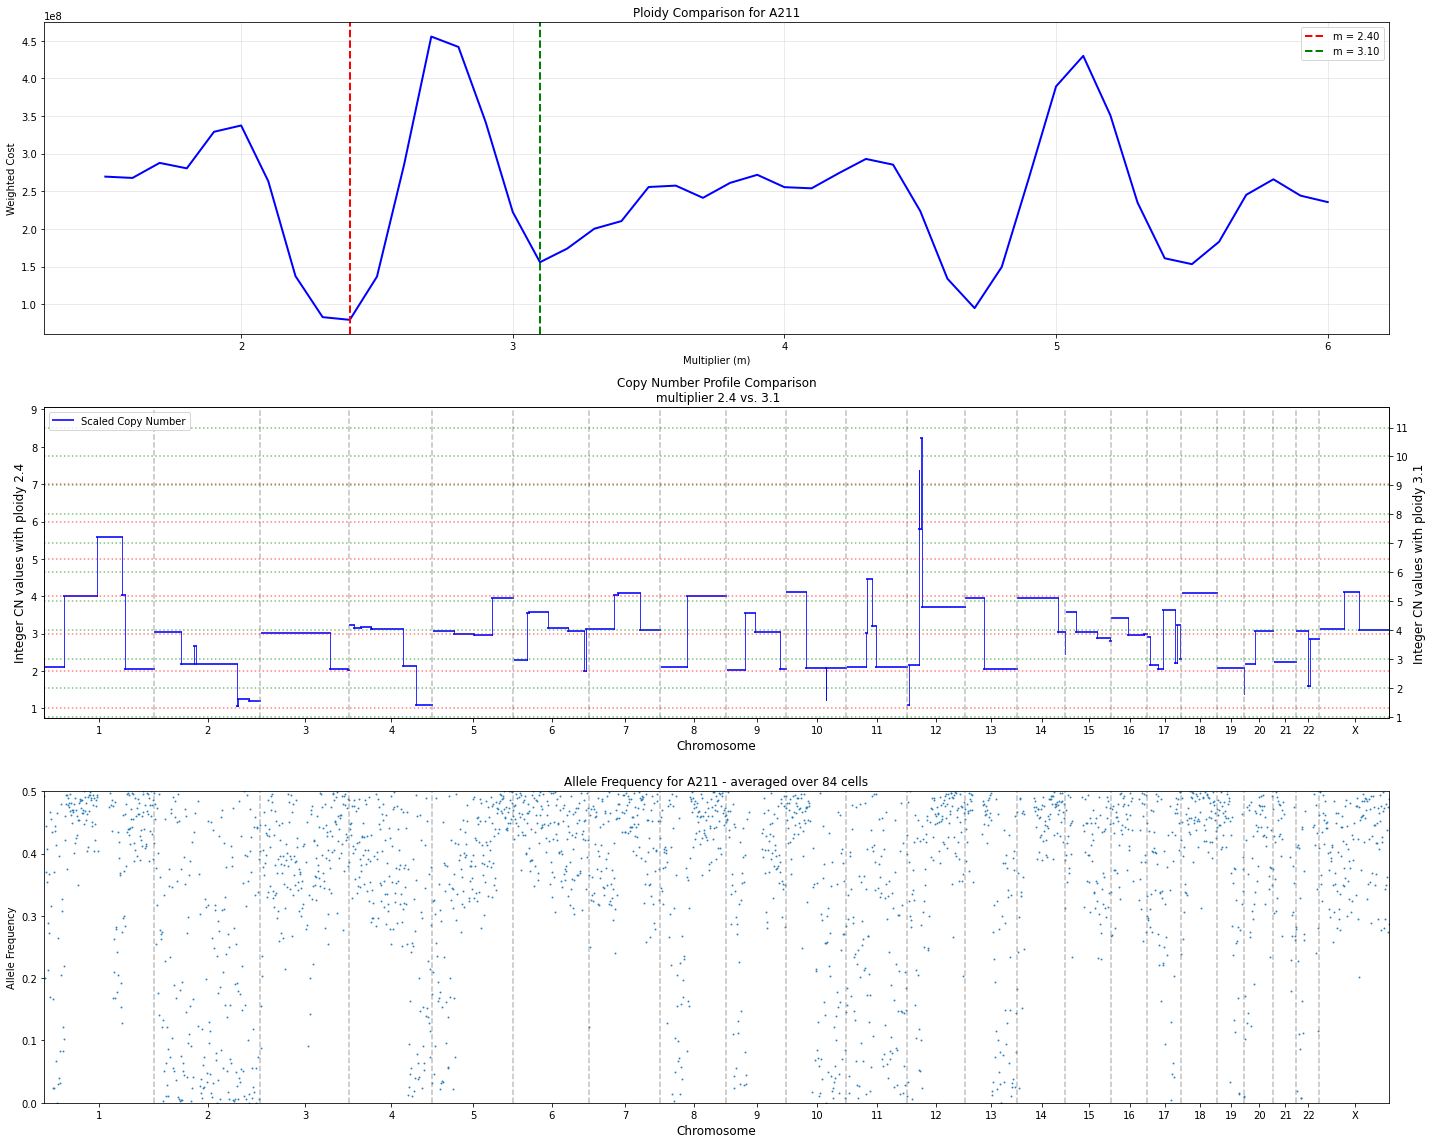

Compared 2.40 vs 3.10 for A211

Creating ploidy comparison for population: A212111


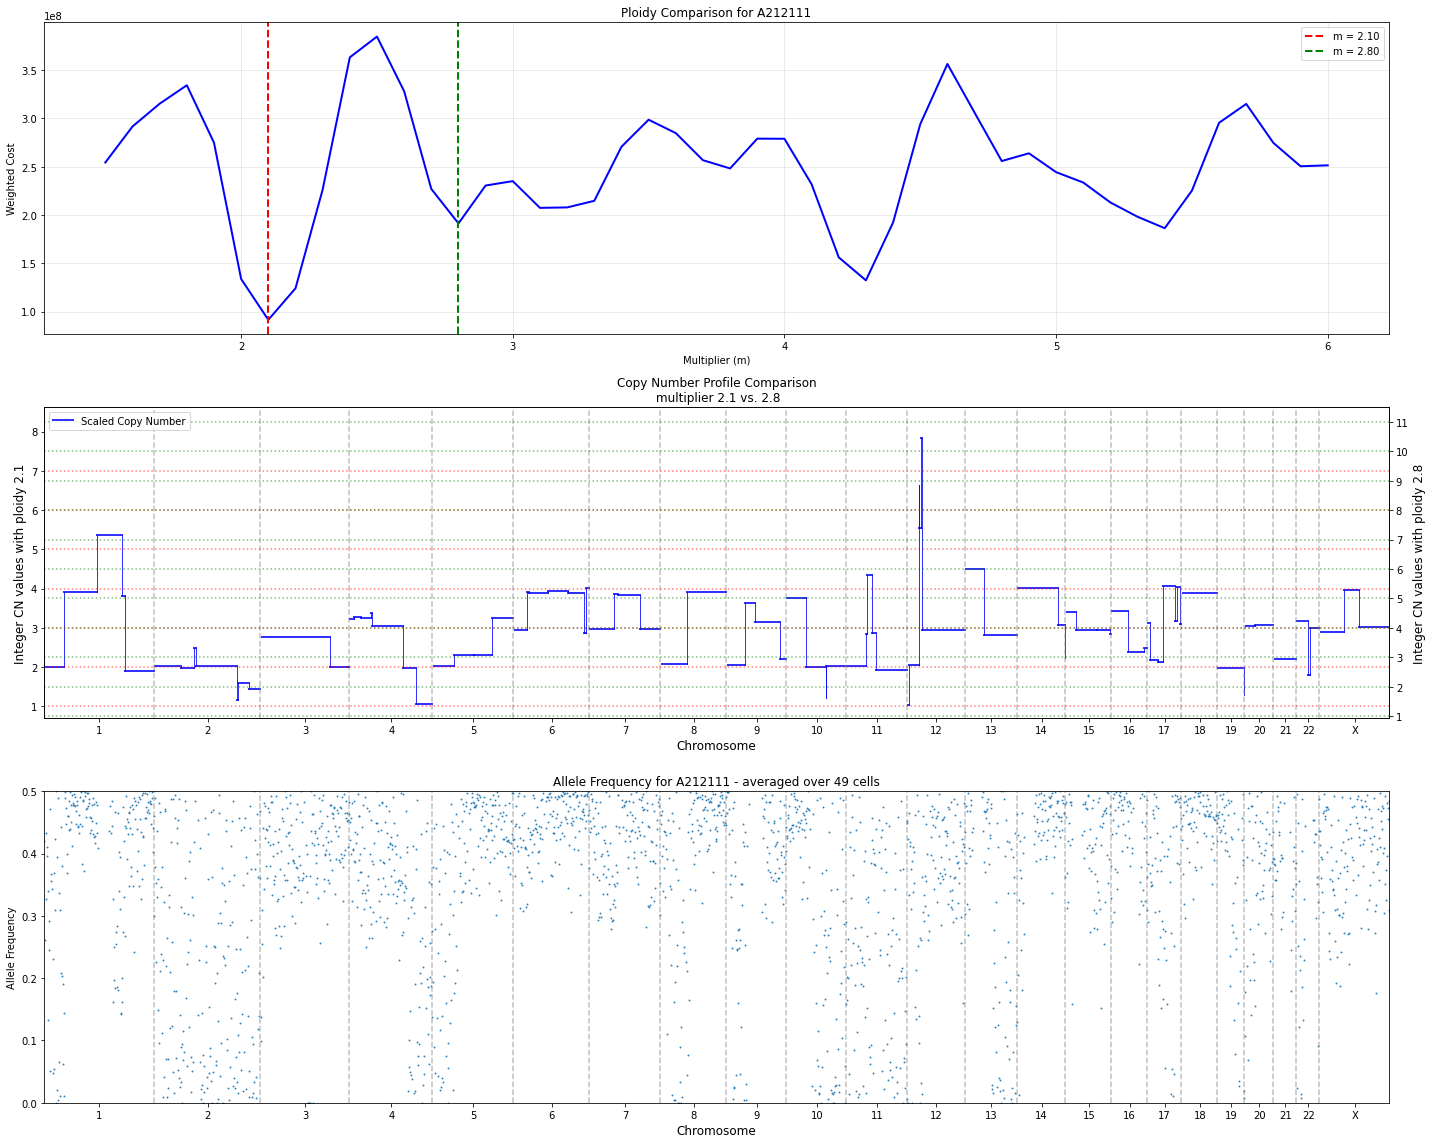

Compared 2.10 vs 2.80 for A212111

Creating ploidy comparison for population: A212112


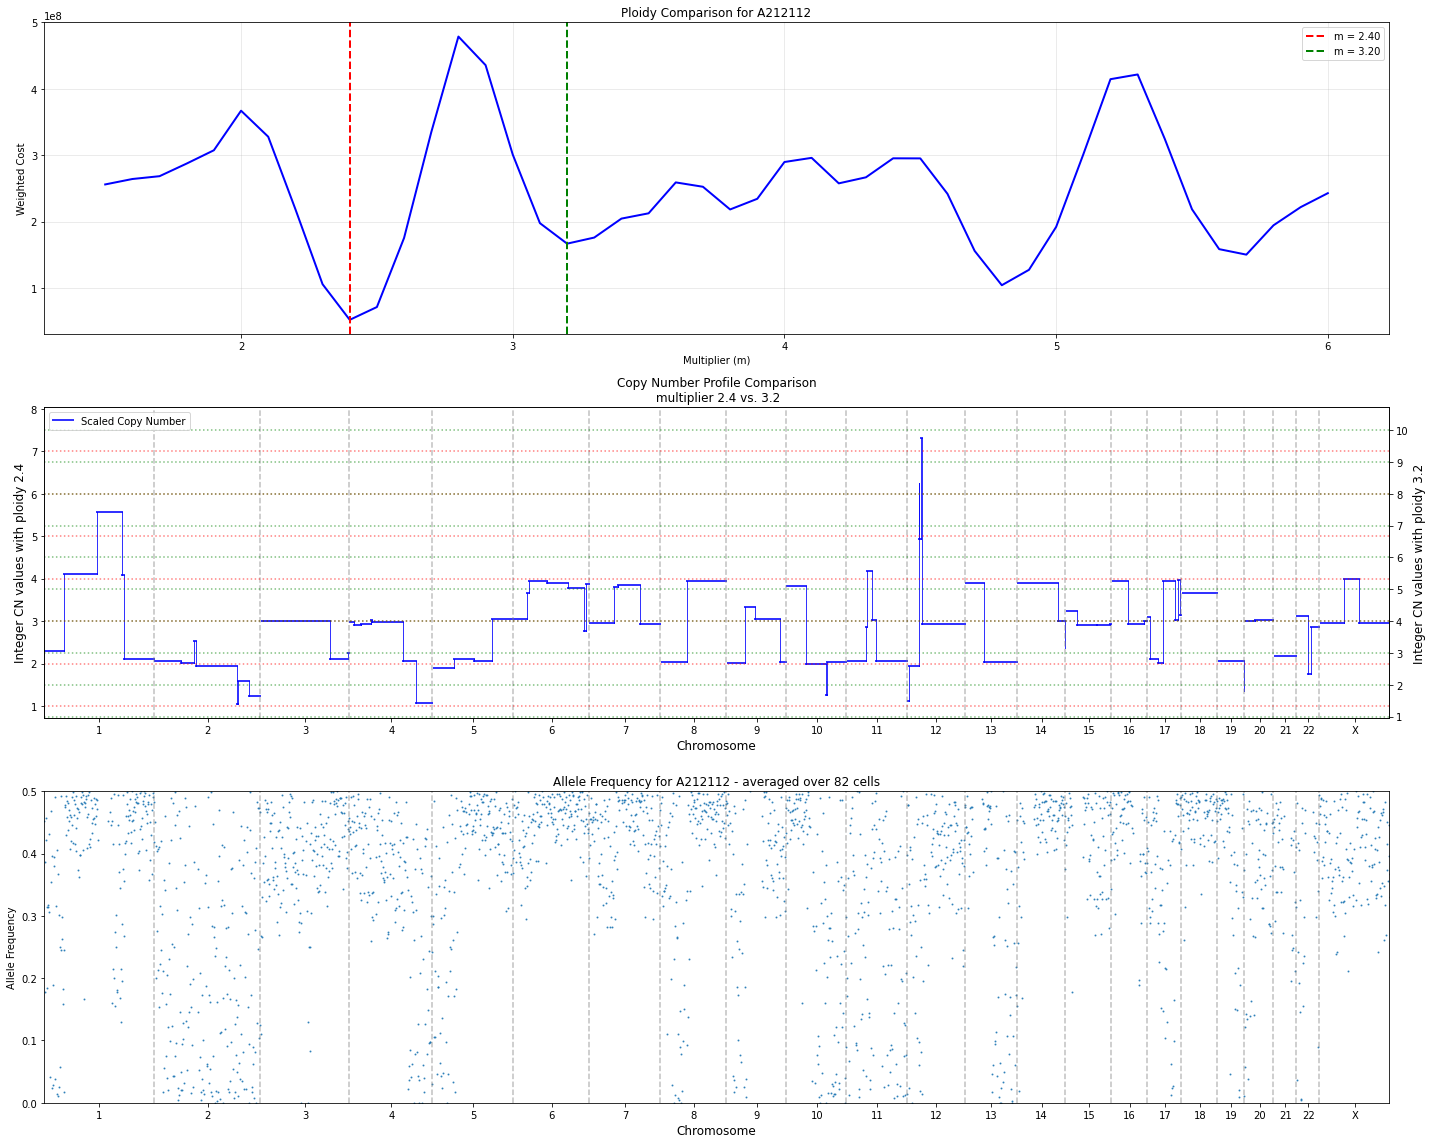

Compared 2.40 vs 3.20 for A212112

Creating ploidy comparison for population: A21212


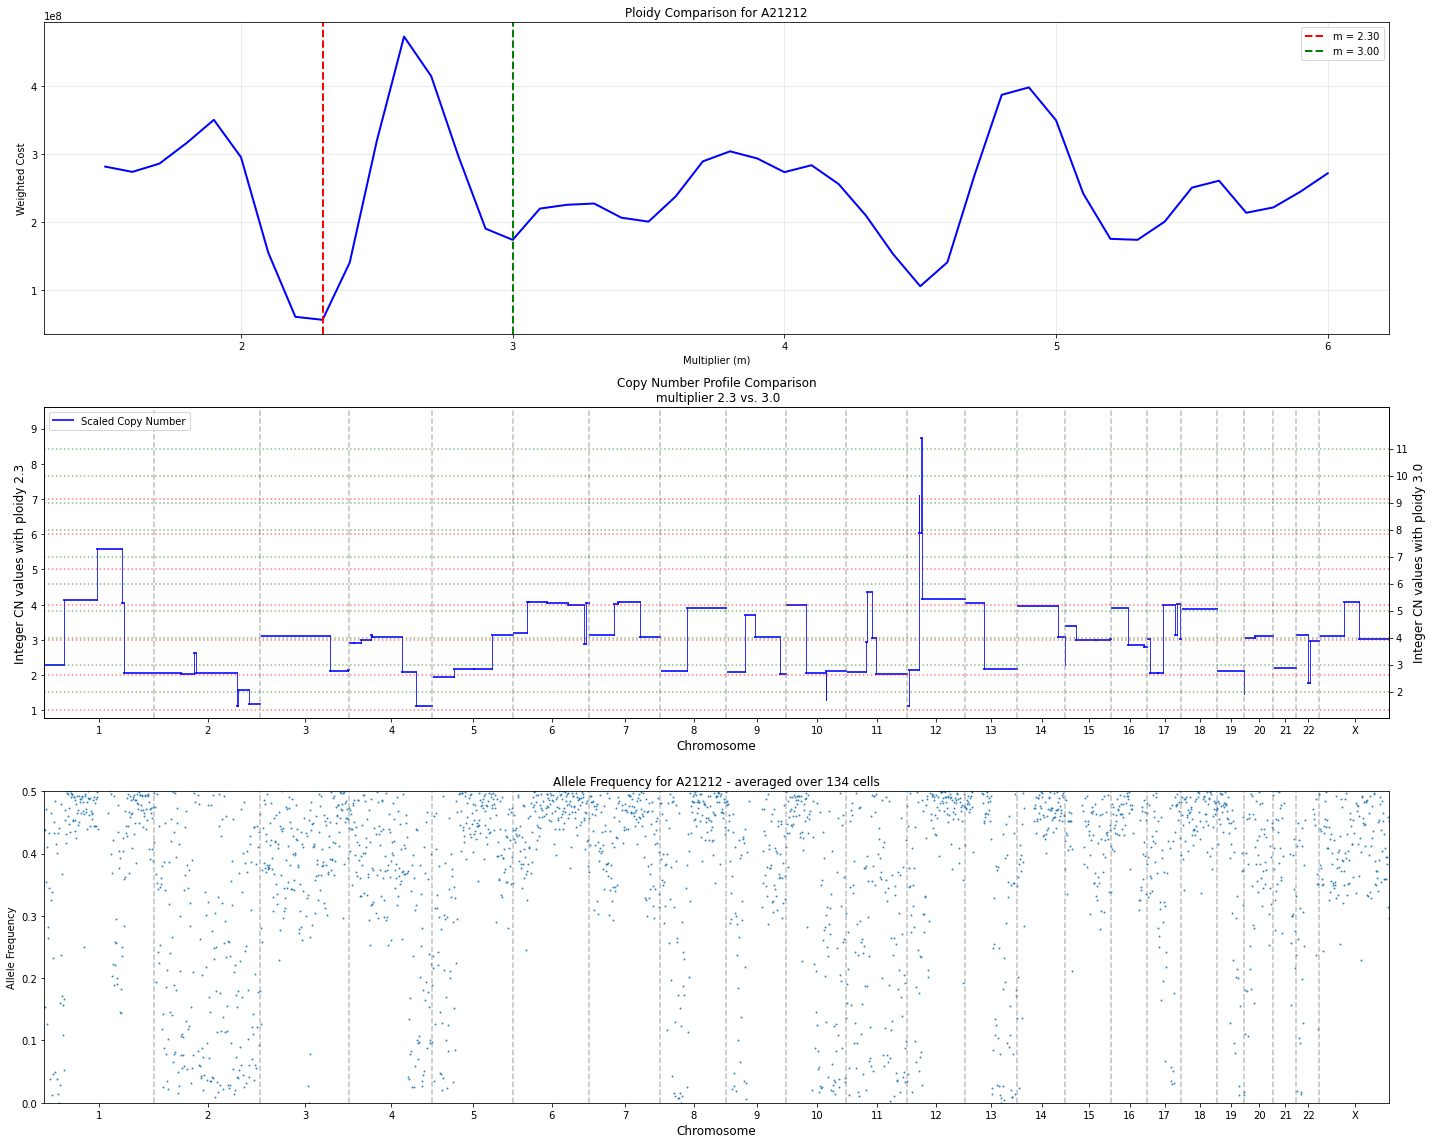

Compared 2.30 vs 3.00 for A21212

Creating ploidy comparison for population: A21221


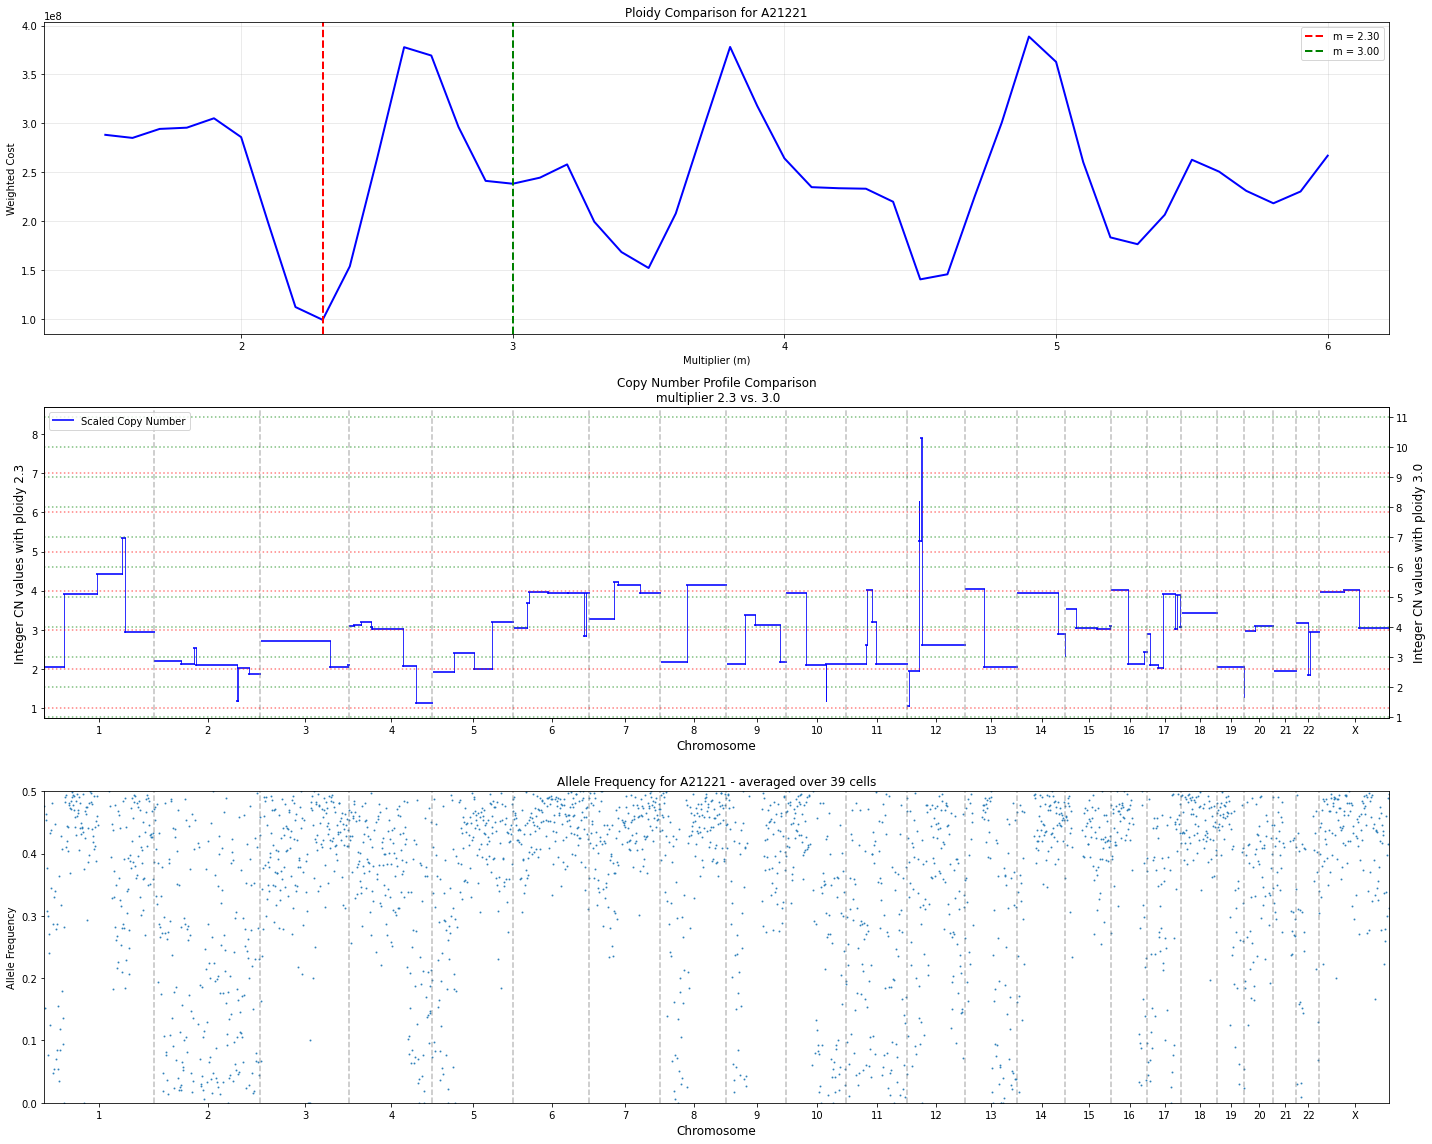

Compared 2.30 vs 3.00 for A21221

Creating ploidy comparison for population: A21222


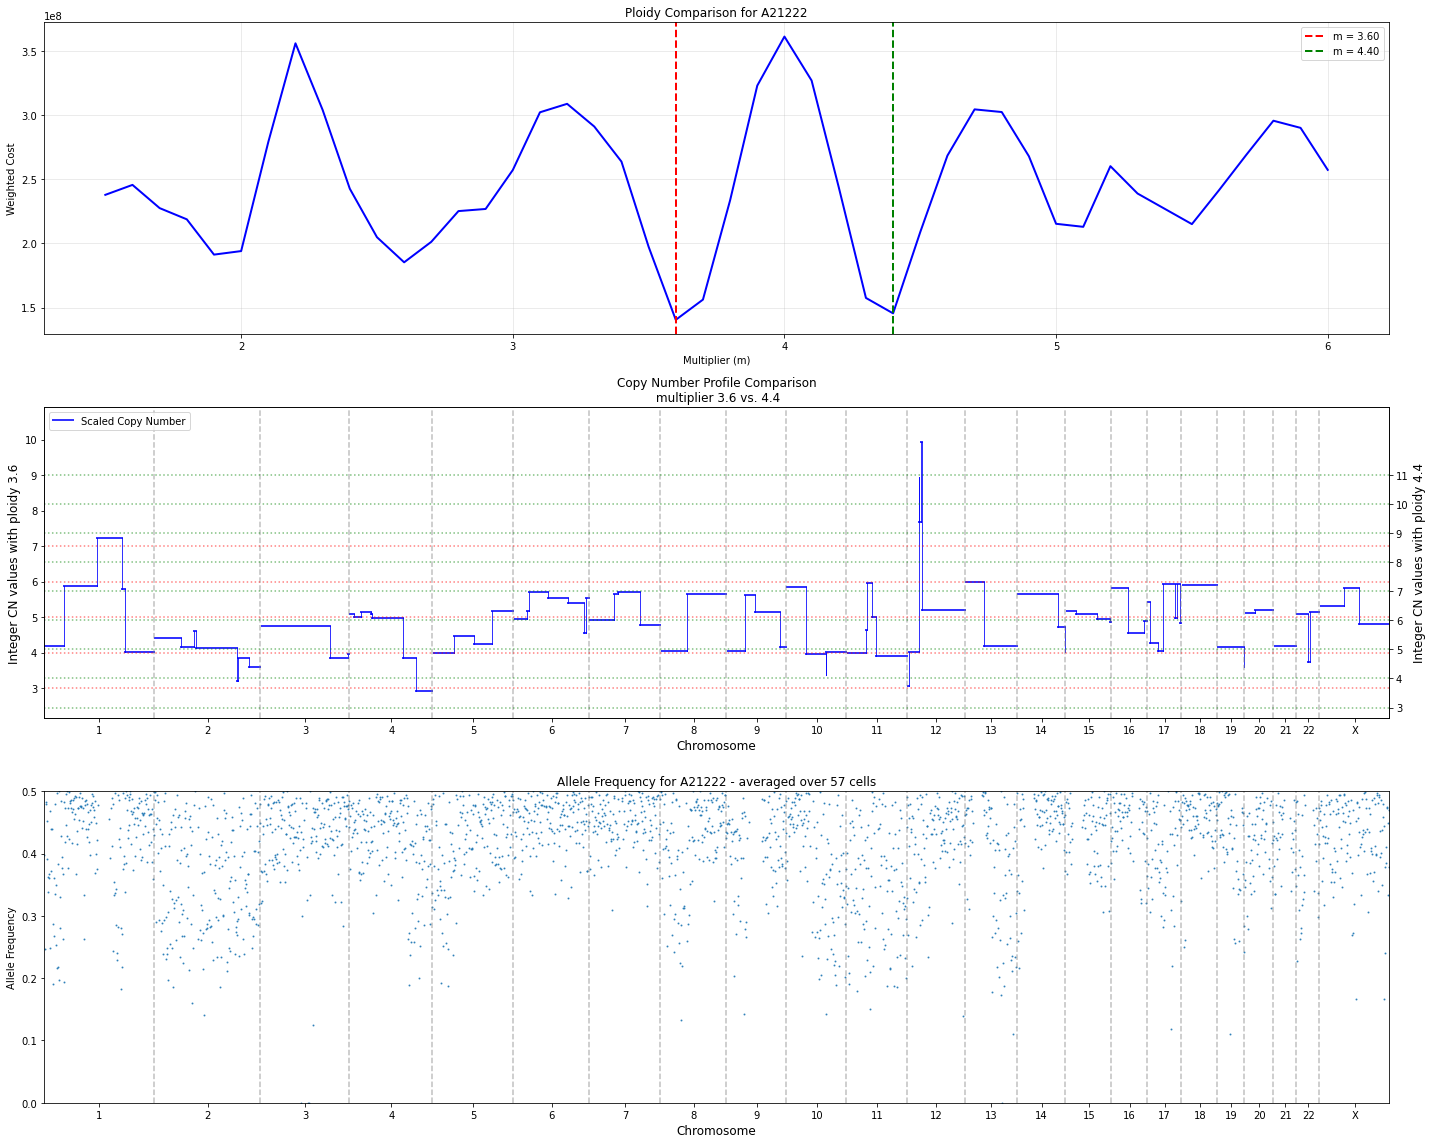

Compared 3.60 vs 4.40 for A21222

Creating ploidy comparison for population: A221


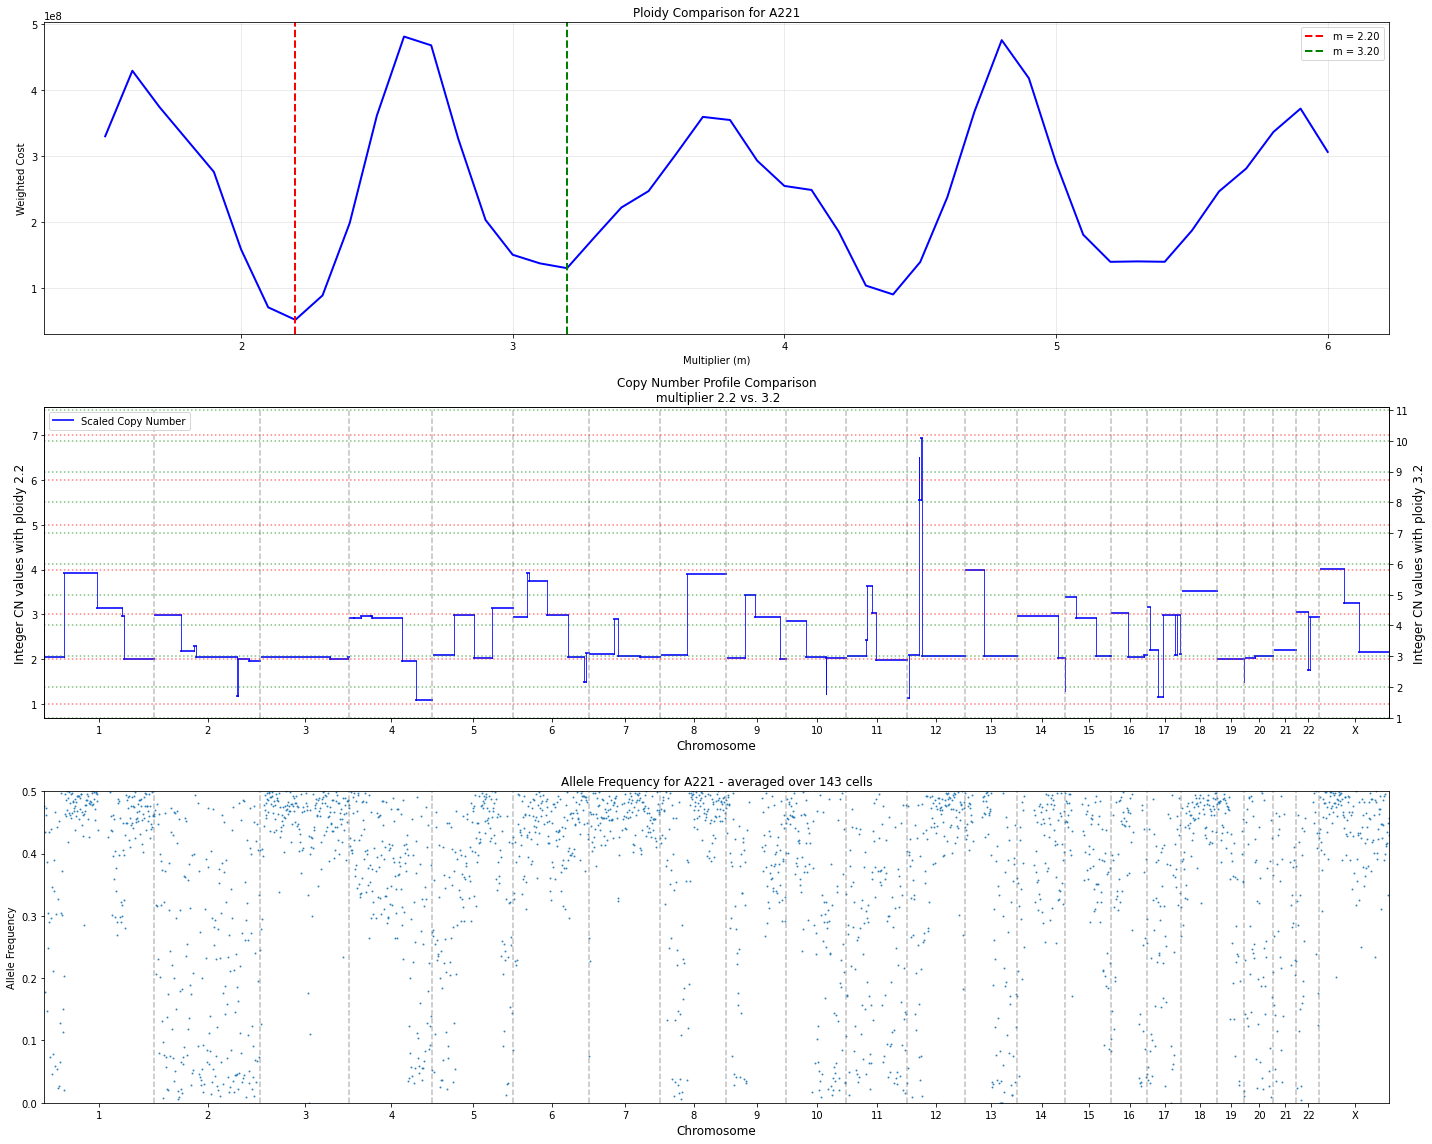

Compared 2.20 vs 3.20 for A221

Creating ploidy comparison for population: A222


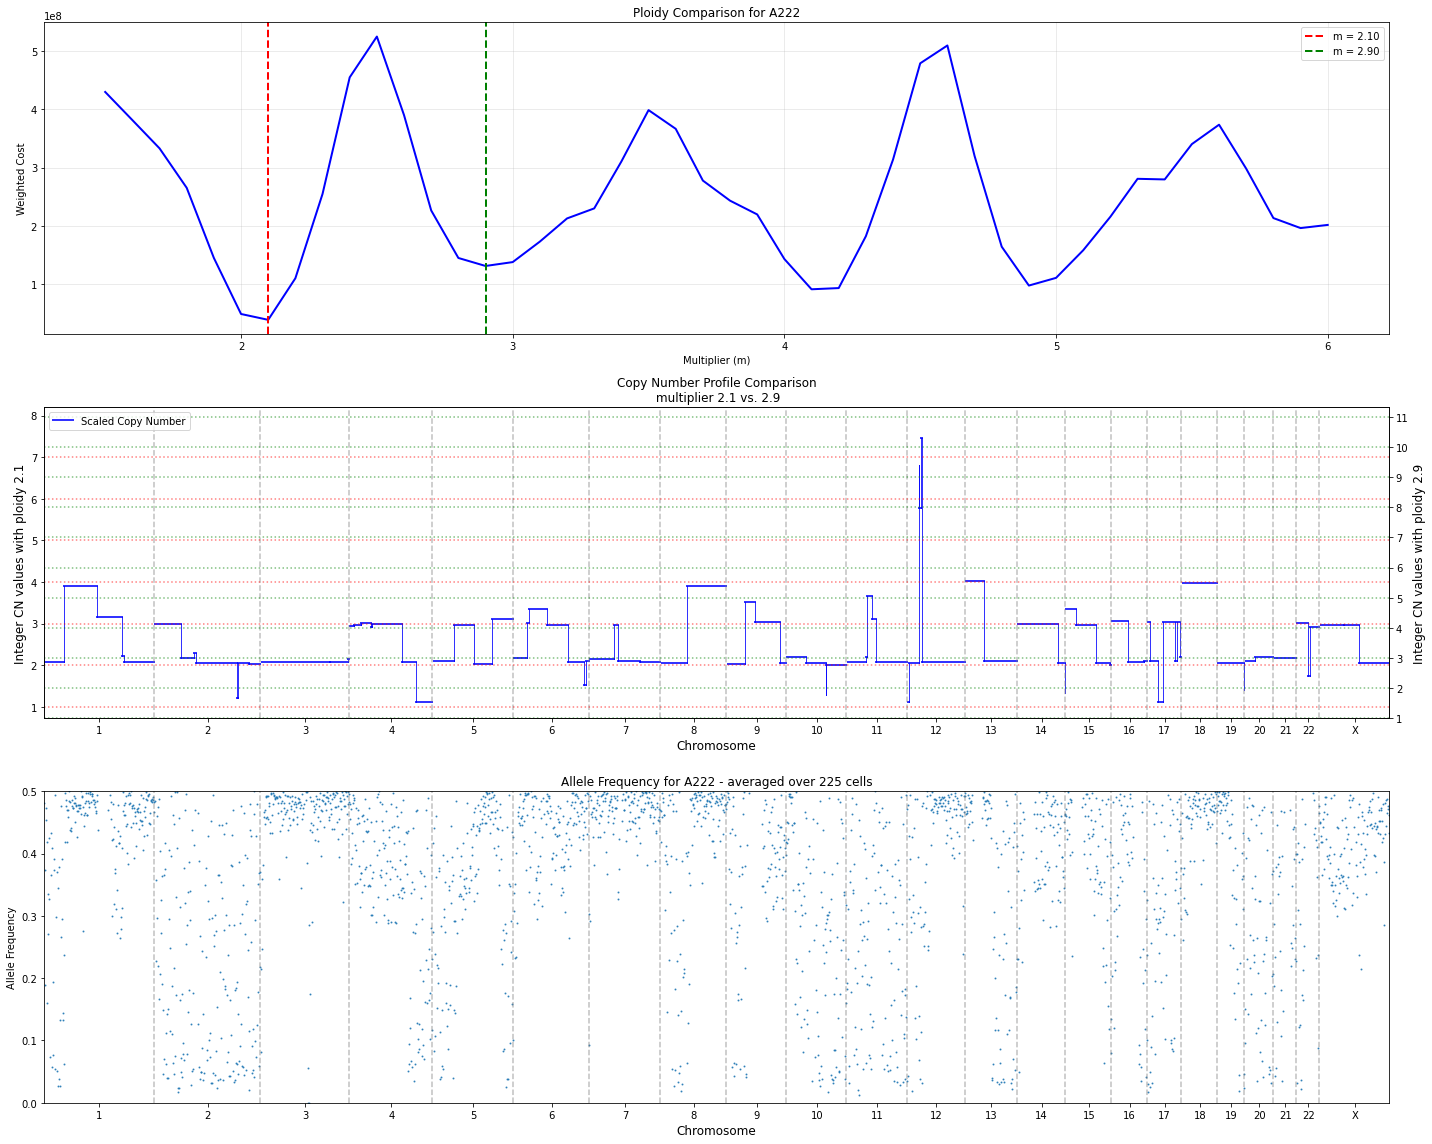

Compared 2.10 vs 2.90 for A222


In [25]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")